###CLEANING E PREPROCESSING DEL DATASET (Dati in migliaia)

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import os

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

file_path = '/content/drive/MyDrive/spostamenti_lavoro_istat.csv'

df = pd.read_csv(file_path, sep=';', encoding='latin1', engine='python')

In [ ]:
# Creo la tabella pivot

df_pivot = df.pivot_table(
    index=['Territorio', 'TIME_PERIOD'],
    columns='Indicatore',
    values='Osservazione',
    aggfunc='sum'
).reset_index()

# Rinominazione colonne
mapping_nomi = {
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: 31 minuti e piÃ¹': 'tempo_31+',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: fino a 15 minuti': 'tempo_0-15',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: bicicletta': 'Bici',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: motocicletta, ciclomotore': 'Moto',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: auto privata (come passeggero)': 'Auto_Passeggero',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: auto privata (come conducente)': 'Auto_Conducente',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: pullman aziendale': 'Pullman_Aziendale',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: pullman, corriera': 'Pullman',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: metropolitana': 'Metro',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: tram, bus': 'Bus_Tram',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: treno': 'Treno',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: usano mezzi di trasporto': 'Usa_Mezzi',
    'Occupati di 15 anni e piÃ¹ che escono di casa abitualmente per andare a lavoro per mezzo di trasporto utilizzato e tempo impiegato: vanno a piedi': 'Piedi'
}

df_pivot.rename(columns=mapping_nomi, inplace=True)
df_pivot.head()

Indicatore,Territorio,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,Pullman,Bus_Tram,Treno,Usa_Mezzi,Piedi
0,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2001,3,36,2,1,32,0,1,0,..,..,..,40,11
1,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2002,3,37,2,1,31,0,1,..,1,..,1,41,9
2,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2003,4,39,2,1,27,0,1,1,..,1,..,44,5
3,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2005,5,41,3,2,31,0,1,..,1,1,1,46,8
4,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2006,4,41,2,1,30,..,1,..,1,1,1,46,8


In [ ]:
# CONVERSIONE DA TESTO A NUMERO
for col in df_pivot.columns:
    if col not in ['Territorio', 'TIME_PERIOD']:
        if df_pivot[col].dtype == 'object':
             # Sostituisce eventuali virgole rimaste con punti
            df_pivot[col] = df_pivot[col].astype(str).str.replace(',', '.')

        #trasforma in NaN i valori che non riesce a convertire
        df_pivot[col] = pd.to_numeric(df_pivot[col], errors='coerce')

In [ ]:
#  Totale Osservazioni (Somma matematica)
df_pivot.drop(columns=['Usa_Mezzi'], inplace=True)
df_pivot['Totale_osservazioni'] = df_pivot['Piedi'].fillna(0) + df_pivot['Auto_Conducente'].fillna(0) + df_pivot['Auto_Passeggero'].fillna(0) + df_pivot['Moto'].fillna(0) + df_pivot['Bici'].fillna(0) + df_pivot['Treno'].fillna(0) + df_pivot['Bus_Tram'].fillna(0) + df_pivot['Metro'].fillna(0) + df_pivot['Pullman'].fillna(0) + df_pivot['Pullman_Aziendale'].fillna(0)
# Tempo mancante 16-30 min
if 'tempo_0-15' in df_pivot.columns and 'tempo_31+' in df_pivot.columns:
    df_pivot['tempo_16-30'] = df_pivot['Totale_osservazioni'] - (df_pivot['tempo_0-15'].fillna(0) + df_pivot['tempo_31+'].fillna(0))
    # Rimuovo eventuali numeri negativi
    df_pivot['tempo_16-30'] = df_pivot['tempo_16-30'].clip(lower=0)

display(df_pivot[['Territorio', 'Totale_osservazioni', 'tempo_0-15', 'tempo_16-30', 'tempo_31+']].head())


Indicatore,Territorio,Totale_osservazioni,tempo_0-15,tempo_16-30,tempo_31+
0,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",51.0,32,16.0,3
1,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",52.0,31,18.0,3
2,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",50.0,27,19.0,4
3,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",58.0,31,22.0,5
4,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",56.0,30,22.0,4


In [ ]:
# Salvo il dataset pulito in un nuovo CSV (utile per non rifare tutto ogni volta)
df_pivot.to_csv('Mobility_Dataset_Cleaned_Pivot.csv', index=False)

#NOTA IMPORTANTE: NON CI SONO I DATI RELATIVI AL 2004 (ISTAT NON LI FORNISCE)

In [ ]:
df = pd.read_csv('Mobility_Dataset_Cleaned_Pivot.csv')
df.head()

,Territorio,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,Pullman,Bus_Tram,Treno,Piedi,Totale_osservazioni,tempo_16-30
0,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2001,3,36,2,1.0,32,0.0,1.0,0.0,NaN,NaN,NaN,11,51.0,16.0
1,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2002,3,37,2,1.0,31,0.0,1.0,NaN,1.0,NaN,1.0,9,52.0,18.0
2,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2003,4,39,2,1.0,27,0.0,1.0,1.0,NaN,1.0,NaN,5,50.0,19.0
3,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2005,5,41,3,2.0,31,0.0,1.0,NaN,1.0,1.0,1.0,8,58.0,22.0
4,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2006,4,41,2,1.0,30,NaN,1.0,NaN,1.0,1.0,1.0,8,56.0,22.0


In [ ]:
# SUDDIVISIONE IN DATASET URBANO E REGIONALE

# Definizione etichette presenti nella colonna 'Territorio' per le tipologie urbane
etichette_urbane = [
    'Centro area metropolitana',
    'Periferia area metropolitana',
    'Fino a 2.000 ab.',
    '2.001 - 10.000 ab.',
    '10.001 - 50.000 ab.',
    '50.001 ab. e piÃ¹'
]

# --- DATASET A: ANALISI URBANISTICA (Per Clustering) ---
df_urban = df[df['Territorio'].isin(etichette_urbane)].copy()

# --- DATASET B: ANALISI TERRITORIALE (Per Regressione con Reddito) ---
df_geo = df[
    (~df['Territorio'].isin(etichette_urbane)) &
    (df['Territorio'] != 'Italia')
].copy()

In [ ]:
from google.colab import data_table
data_table.enable_dataframe_formatter()
#per disattivarlo dopo, uso data_table.disable_dataframe_formatter()

display(df_urban)

,Territorio,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,Pullman,Bus_Tram,Treno,Piedi,Totale_osservazioni,tempo_16-30
23,10.001 - 50.000 ab.,2001,582,3563,334,131.0,2654,27.0,132.0,45.0,110.0,85.0,137.0,590,5154.0,1918.0
24,10.001 - 50.000 ab.,2002,556,3818,322,170.0,2887,28.0,155.0,45.0,96.0,84.0,122.0,654,5494.0,2051.0
25,10.001 - 50.000 ab.,2003,571,3921,286,165.0,2891,49.0,235.0,64.0,83.0,77.0,141.0,594,5615.0,2153.0
26,10.001 - 50.000 ab.,2005,630,3920,346,193.0,2820,63.0,137.0,58.0,106.0,84.0,144.0,588,5639.0,2189.0
27,10.001 - 50.000 ab.,2006,758,4075,338,186.0,2883,68.0,150.0,39.0,95.0,83.0,142.0,573,5749.0,2108.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
432,Periferia area metropolitana,2020,719,2290,146,73.0,922,201.0,107.0,2.0,104.0,113.0,189.0,275,3500.0,1859.0
433,Periferia area metropolitana,2021,668,2266,142,65.0,821,114.0,108.0,6.0,70.0,97.0,147.0,279,3294.0,1805.0
434,Periferia area metropolitana,2022,649,2353,139,72.0,1009,121.0,72.0,6.0,71.0,67.0,126.0,363,3390.0,1732.0
435,Periferia area metropolitana,2023,561,2410,160,71.0,988,120.0,68.0,6.0,100.0,76.0,110.0,288,3409.0,1860.0


In [ ]:
display(df_geo)

,Territorio,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,Pullman,Bus_Tram,Treno,Piedi,Totale_osservazioni,tempo_16-30
0,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2001,3,36,2,1.0,32,0.0,1.0,0.0,NaN,NaN,NaN,11,51.0,16.0
1,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2002,3,37,2,1.0,31,0.0,1.0,NaN,1.0,NaN,1.0,9,52.0,18.0
2,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2003,4,39,2,1.0,27,0.0,1.0,1.0,NaN,1.0,NaN,5,50.0,19.0
3,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2005,5,41,3,2.0,31,0.0,1.0,NaN,1.0,1.0,1.0,8,58.0,22.0
4,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2006,4,41,2,1.0,30,NaN,1.0,NaN,1.0,1.0,1.0,8,56.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
616,Veneto,2020,268,1511,70,87.0,791,0.0,47.0,0.0,22.0,50.0,30.0,122,1939.0,880.0
617,Veneto,2021,302,1551,76,133.0,783,0.0,57.0,6.0,30.0,45.0,31.0,144,2073.0,988.0
618,Veneto,2022,262,1560,82,127.0,820,1.0,45.0,2.0,27.0,72.0,31.0,142,2089.0,1007.0
619,Veneto,2023,288,1546,83,130.0,869,7.0,39.0,2.0,39.0,61.0,38.0,183,2128.0,971.0


#ANALISI SULL'UTILIZZO DELLA MACCHINA E DEI MEZZI PUBBLICI NEL TEMPO

In [ ]:
# CREAZIONE FEATURE PERCENTUALI ---
# Lavoro su una copia per non toccare l'originale
df_analysis = df_urban.copy()

# 1. Calcolo delle % di utilizzo mezzi (rispetto al totale osservazioni)
df_analysis['Perc_Auto'] = (((df_analysis['Auto_Conducente'] + df_analysis['Auto_Passeggero']) / df_analysis['Totale_osservazioni']) * 100).round(2)
df_analysis['Perc_Moto'] = ((df_analysis['Moto'] / df_analysis['Totale_osservazioni']) * 100).round(2)
df_analysis['Perc_Public_Transport'] = (((df_analysis['Treno'].fillna(0) + df_analysis['Bus_Tram'].fillna(0) + df_analysis['Metro'].fillna(0) + df_analysis['Pullman'].fillna(0) + df_analysis['Pullman_Aziendale'].fillna(0)) / df_analysis['Totale_osservazioni']) * 100).round(2)
df_analysis['Perc_Active_Mobility'] = (((df_analysis['Piedi'].fillna(0) + df_analysis['Bici'].fillna(0)) / df_analysis['Totale_osservazioni']) * 100).round(2)

# 2. Calcolo delle % dei tempi (più di 30 min)
# Nota: qui il denominatore è Totale_osservazioni (che abbiamo calcolato come somma di chi si sposta)
df_analysis['Perc_Long_Commuting'] = ((df_analysis['tempo_31+'] / df_analysis['Totale_osservazioni']) * 100).round(2)

# Pulizia dei Nan
df_analysis = df_analysis.fillna(0)

display(df_analysis[['Territorio', 'TIME_PERIOD', 'Perc_Auto', 'Perc_Moto', 'Perc_Public_Transport', 'Perc_Active_Mobility', 'Perc_Long_Commuting']])

,Territorio,TIME_PERIOD,Perc_Auto,Perc_Moto,Perc_Public_Transport,Perc_Active_Mobility,Perc_Long_Commuting
23,10.001 - 50.000 ab.,2001,75.61,2.56,7.84,13.99,11.29
24,10.001 - 50.000 ab.,2002,75.35,2.82,6.83,15.00,10.12
25,10.001 - 50.000 ab.,2003,74.92,4.19,7.37,13.52,10.17
26,10.001 - 50.000 ab.,2005,75.65,2.43,8.07,13.85,11.17
27,10.001 - 50.000 ab.,2006,76.76,2.61,7.43,13.20,13.18
...,...,...,...,...,...,...,...
432,Periferia area metropolitana,2020,69.60,3.06,17.40,9.94,20.54
433,Periferia area metropolitana,2021,73.10,3.28,13.18,10.44,20.28
434,Periferia area metropolitana,2022,73.51,2.12,11.53,12.83,19.14
435,Periferia area metropolitana,2023,75.39,1.99,12.09,10.53,16.46


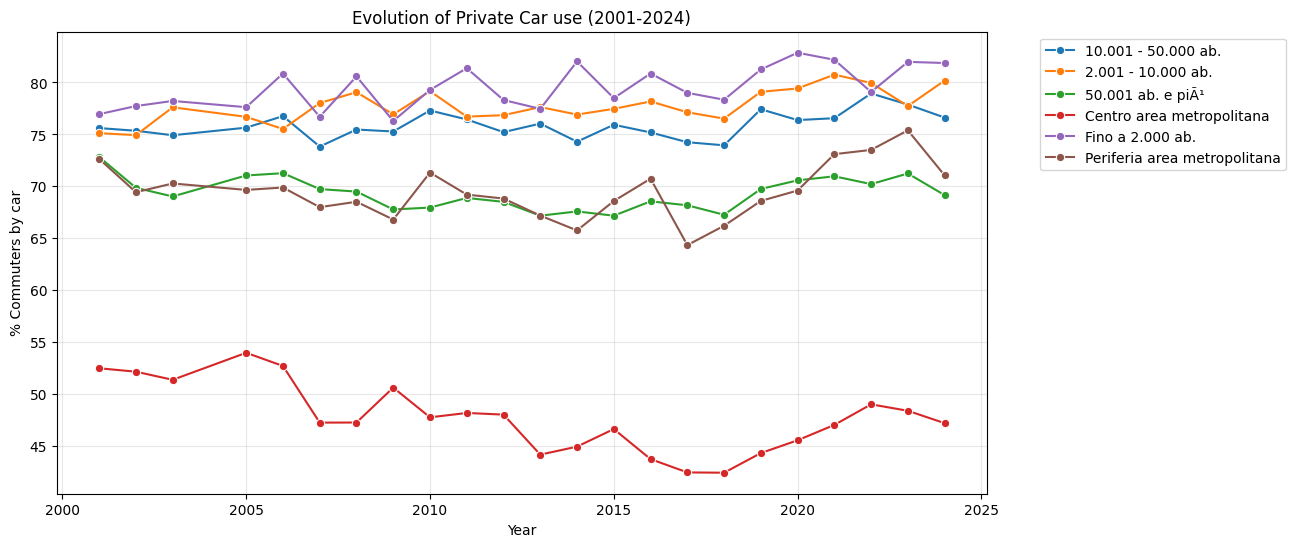

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# ANALISI TEMPORALE (2001-2024)
plt.figure(figsize=(12, 6))

# Vogliamo vedere come cambia l'uso dell'auto nelle diverse zone urbanistiche
sns.lineplot(
    data=df_analysis,
    x='TIME_PERIOD',
    y='Perc_Auto',
    hue='Territorio',
    marker='o'
)

plt.title('Evolution of Private Car use (2001-2024)')
plt.ylabel('% Commuters by car')
plt.xlabel('Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

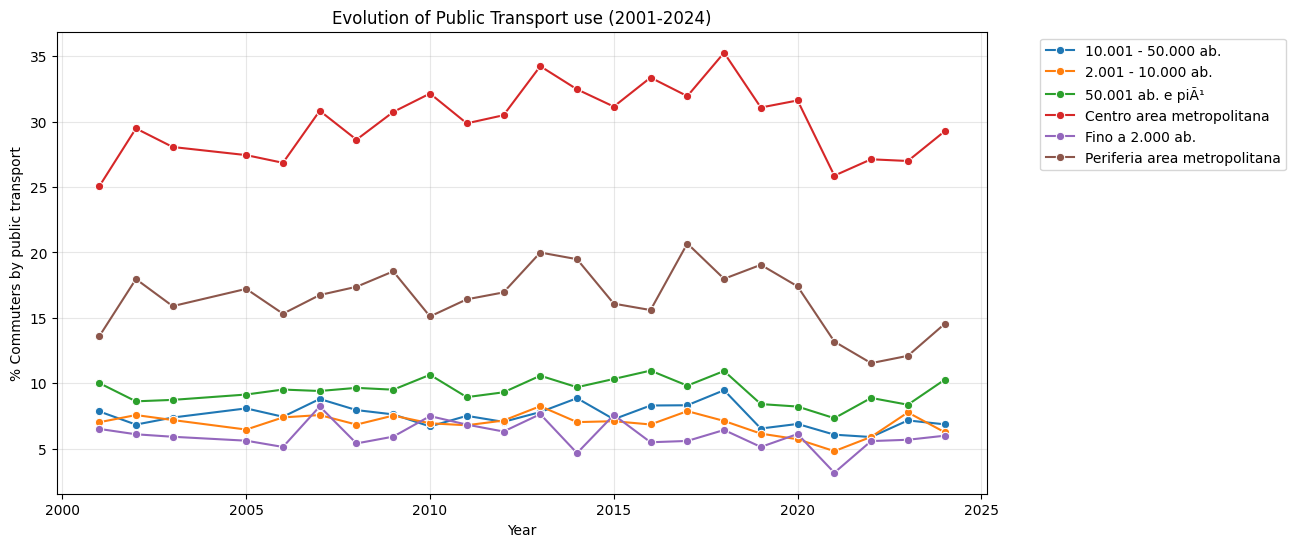

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_analysis,
    x='TIME_PERIOD',
    y='Perc_Public_Transport',
    hue='Territorio',
    marker='o'
)

plt.title('Evolution of Public Transport use (2001-2024)')
plt.ylabel('% Commuters by public transport')
plt.xlabel('Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

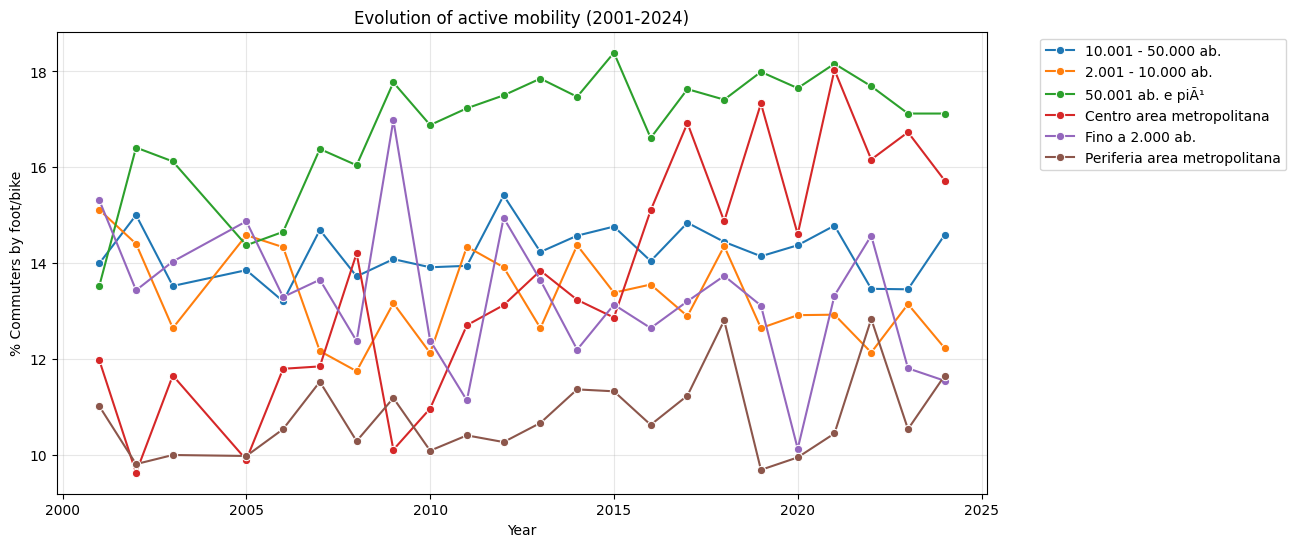

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_analysis,
    x='TIME_PERIOD',
    y='Perc_Active_Mobility',
    hue='Territorio',
    marker='o'
)

plt.title('Evolution of active mobility (2001-2024)')
plt.ylabel('% Commuters by foot/bike')
plt.xlabel('Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

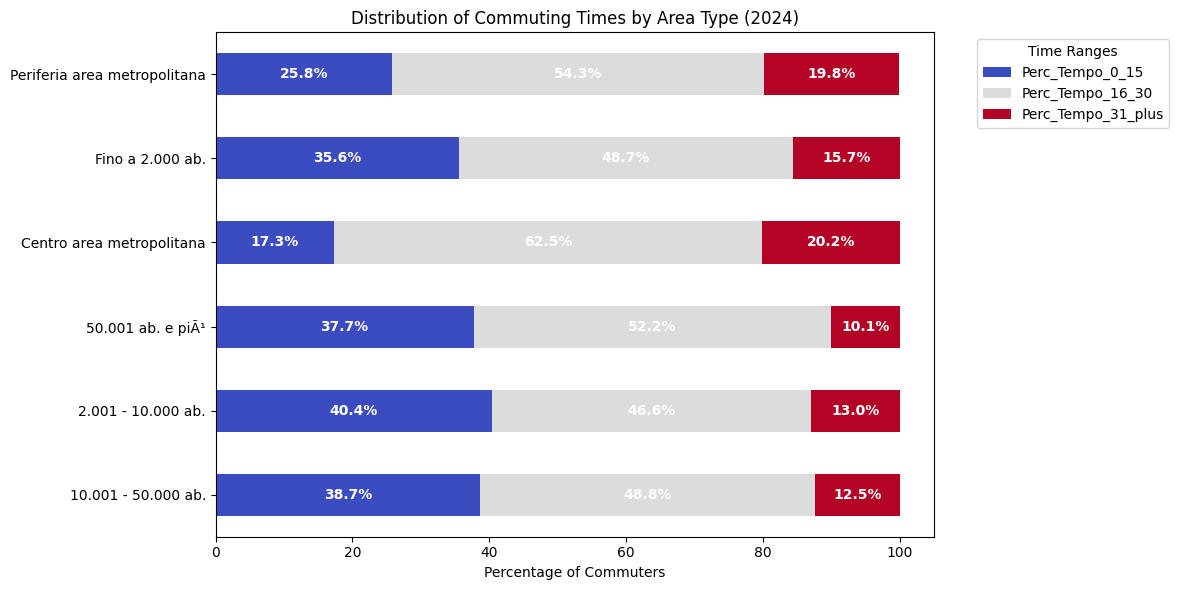

In [ ]:
# PREPARAZIONE DATI TEMPI
df_analysis['Perc_Tempo_0_15'] = ((df_analysis['tempo_0-15'] / df_analysis['Totale_osservazioni']) * 100).round(1)
df_analysis['Perc_Tempo_16_30'] = ((df_analysis['tempo_16-30'] / df_analysis['Totale_osservazioni']) * 100).round(1)
df_analysis['Perc_Tempo_31_plus'] = ((df_analysis['tempo_31+'] / df_analysis['Totale_osservazioni']) * 100).round(1)

# Filtro il dataset sul 2024
last_year = df_analysis['TIME_PERIOD'].max()
df_times = df_analysis[df_analysis['TIME_PERIOD'] == last_year].copy()

cols_times = ['Territorio', 'Perc_Tempo_0_15', 'Perc_Tempo_16_30', 'Perc_Tempo_31_plus']
df_plot_times = df_times[cols_times].set_index('Territorio')

import matplotlib.pyplot as plt

ax = df_plot_times.plot(kind='barh', stacked=True, figsize=(12, 6), colormap='coolwarm')
plt.title(f'Distribution of Commuting Times by Area Type ({last_year})')
plt.xlabel('Percentage of Commuters')
plt.ylabel('')
plt.legend(title='Time Ranges', bbox_to_anchor=(1.05, 1), loc='upper left')

for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', label_type='center', color='white', weight='bold')

plt.tight_layout()
plt.show()


si noti qui la quasi totale uniformità di tutte le aree urbane sotto i 50k. è evidente anche un'altra informazione: tra centro e periferia delle aree metropolitane la percentuale di tempi>31 min è molto simile, ma cambia di piu dell'8% quella nelle altre 2 fasce (il tempo medio nel centro è decisamente piu alto)

#CLUSTERING DEI GRUPPI PER VEDERE SE LE DIFFERENZE TRA LE TIPOLOGIA DI AREE URBANE SONO NETTE


--- PROFILI DEI CLUSTER IDENTIFICATI ---


,Perc_Auto,Perc_Public_Transport,Perc_Active_Mobility,Perc_Long_Commuting
Cluster,,,,
0,47.743043,29.998261,13.618696,21.507826
1,77.478732,6.936056,13.570986,13.328873
2,69.509130,16.462174,10.786087,21.605217
3,69.306667,9.254286,17.257143,10.074762


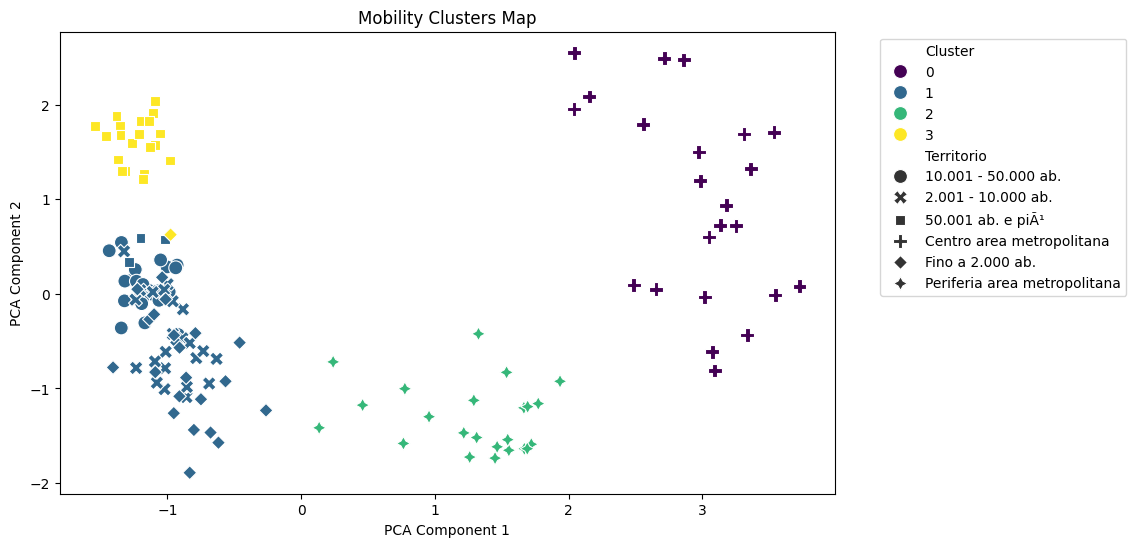

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# CLUSTERING ---

# Selezione colonne percentuali
features_clustering = ['Perc_Auto', 'Perc_Public_Transport', 'Perc_Active_Mobility', 'Perc_Long_Commuting']
X = df_analysis[features_clustering]

#Standardizzazione
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#Applico K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10) #devo decidere se è meglio 4 o 6 (con 6 distingue bene solo alcune delle 6 categorie mentre mischia le città di media grandezza) 4 è meglio
df_analysis['Cluster'] = kmeans.fit_predict(X_scaled)

print("\n--- PROFILI DEI CLUSTER IDENTIFICATI ---")
cluster_summary = df_analysis.groupby('Cluster')[features_clustering].mean()
display(cluster_summary)

#Visualizzazione 2D dei Cluster con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_analysis['Cluster'],
    palette='viridis',
    s=100,
    style=df_analysis['Territorio']
)
plt.title("Mobility Clusters Map")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

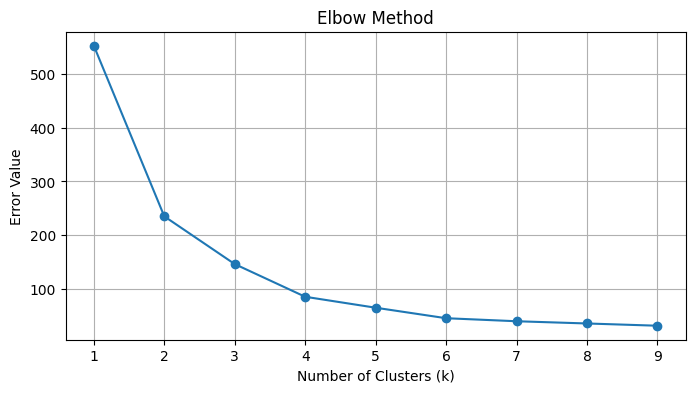


--- Come si distribuiscono le tipologie ISTAT nei Cluster ML? ---


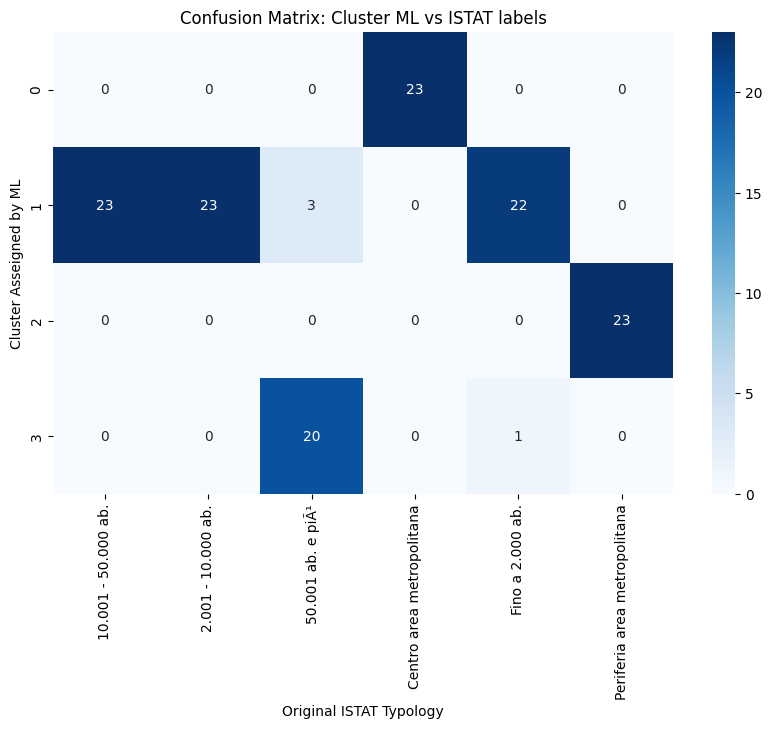

In [ ]:
# ANALISI AVANZATA CLUSTERING (Urban)
import matplotlib.pyplot as plt
import seaborn as sns

# 1. METODO GOMITO
inertia = []
K_range = range(1, 10)

for k in K_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_scaled)
    inertia.append(kmeans_test.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Error Value')
plt.grid(True)
plt.show()

# 2. CONFRONTO CLUSTER vs ETICHETTE ORIGINALI
if 'Cluster' in df_analysis.columns:
    print("\n--- Come si distribuiscono le tipologie ISTAT nei Cluster ML? ---")
    cross_tab = pd.crosstab(df_analysis['Cluster'], df_analysis['Territorio'])

    plt.figure(figsize=(10, 6))
    sns.heatmap(cross_tab, annot=True, fmt='d', cmap='Blues')
    plt.title("Confusion Matrix: Cluster ML vs ISTAT labels")
    plt.ylabel("Cluster Asseigned by ML")
    plt.xlabel("Original ISTAT Typology")
    plt.show()

ho scelto 4 cluster seguendo la regola del gomito. L'analisi ML dimostra che sotto i 50.000 abitanti il comportamento di mobilità è identico, rendendo superflua la distinzione ISTAT. a maggior ragione il numero di cluster uguale a 4 è ottimale: le citta da 50k o piu, i centri di aree metropolitane e le periferie sono molto ben distinti tra loro

#EDA: ANALISI REGIONALE

/tmp/ipython-input-1018269183.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_last_year, x='Perc_Auto', y='Territorio', palette='Reds_r')


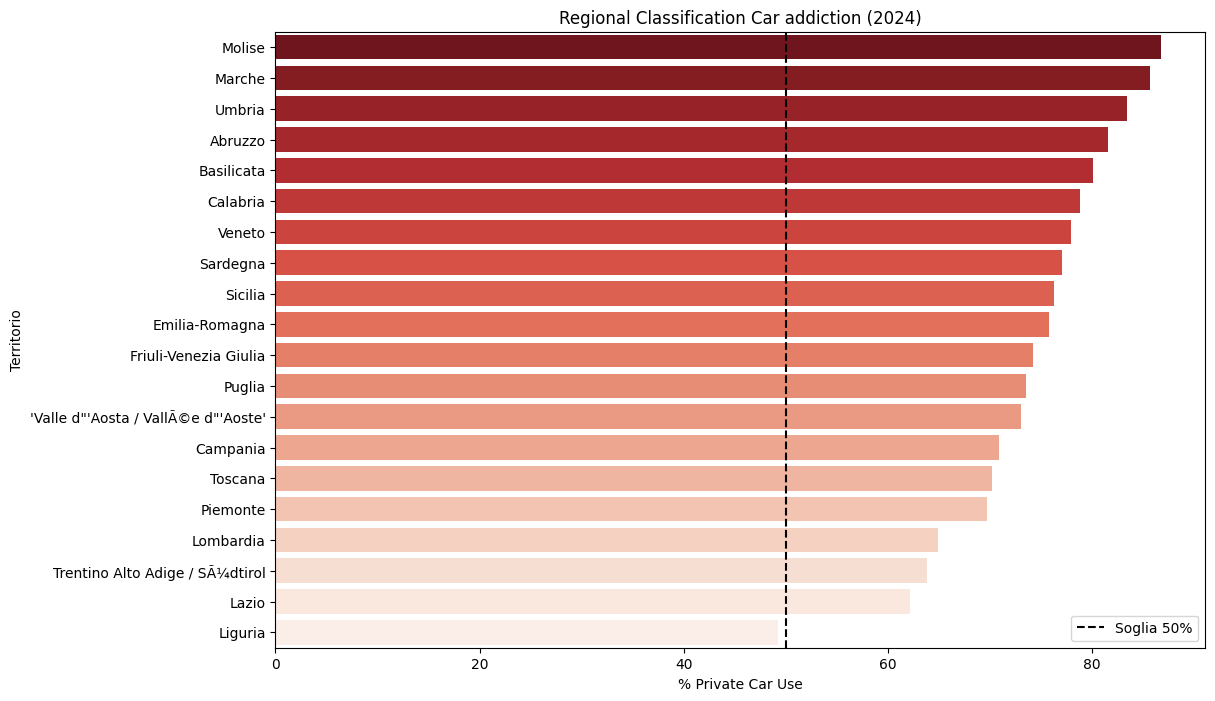

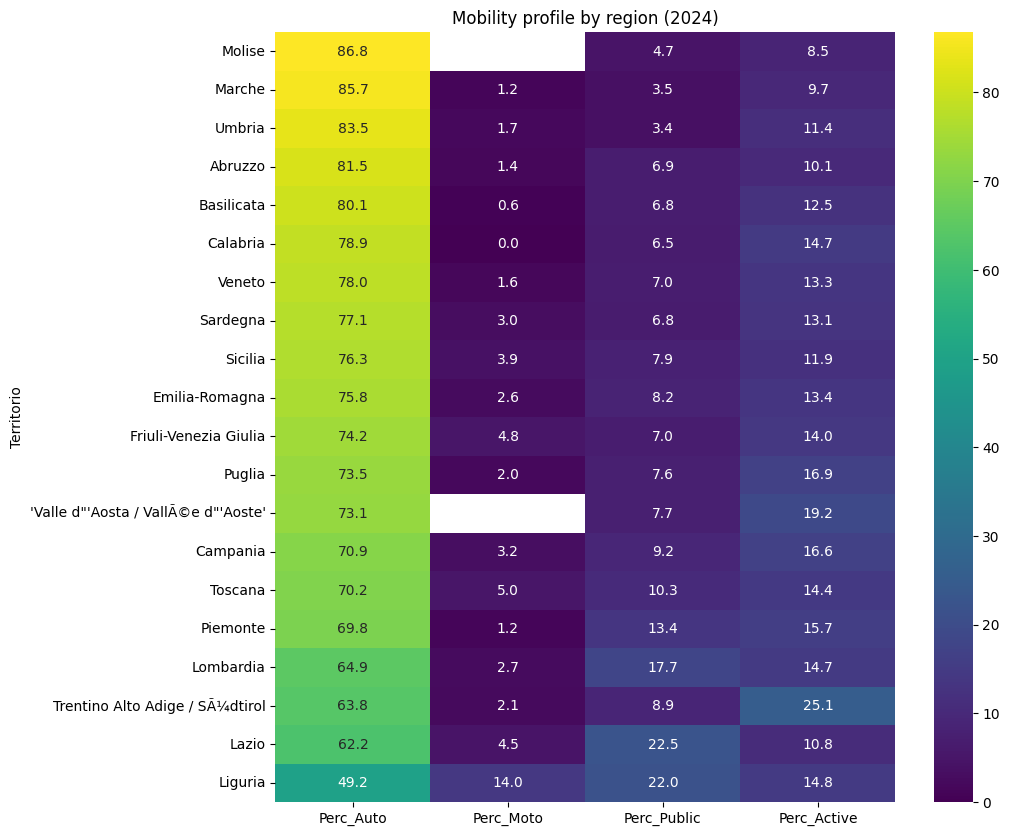

In [ ]:
# PREPARAZIONE df_geo
df_geo_anal = df_geo.copy()

# Calcolo percentuali
df_geo_anal['Perc_Auto'] = (((df_geo_anal['Auto_Conducente'] + df_geo_anal['Auto_Passeggero'])/ df_geo_anal['Totale_osservazioni']) * 100).round(2)
df_geo_anal['Perc_Moto'] = ((df_geo_anal['Moto'] / df_geo_anal['Totale_osservazioni']) * 100).round(2)
df_geo_anal['Perc_Public'] = (((df_geo_anal['Treno'].fillna(0) + df_geo_anal['Bus_Tram'].fillna(0) + df_geo_anal['Metro'].fillna(0) + df_geo_anal['Pullman'].fillna(0) + df_geo_anal['Pullman_Aziendale'].fillna(0)) / df_geo_anal['Totale_osservazioni']) * 100).round(2)
df_geo_anal['Perc_Active'] = (((df_geo_anal['Piedi'].fillna(0) + df_geo_anal['Bici'].fillna(0)) / df_geo_anal['Totale_osservazioni']) * 100).round(2)


# Filtro solo sul 2024
last_year = df_geo_anal['TIME_PERIOD'].max()
df_last_year = df_geo_anal[df_geo_anal['TIME_PERIOD'] == last_year].sort_values('Perc_Auto', ascending=False)

#  Classifica Dipendenza Auto (Ultimo Anno)
plt.figure(figsize=(12, 8))
sns.barplot(data=df_last_year, x='Perc_Auto', y='Territorio', palette='Reds_r')
plt.title(f'Regional Classification Car addiction ({last_year})')
plt.xlabel('% Private Car Use')
plt.axvline(x=50, color='k', linestyle='--', label='Soglia 50%') # Linea di riferimento
plt.legend()
plt.show()

# 2. HEATMAP COMPLETA
cols_heatmap = ['Perc_Auto', 'Perc_Moto', 'Perc_Public', 'Perc_Active']
heatmap_data = df_last_year.set_index('Territorio')[cols_heatmap]

plt.figure(figsize=(10, 10))
sns.heatmap(heatmap_data, annot=True, cmap='viridis', fmt='.1f')
plt.title(f'Mobility profile by region ({last_year})')
plt.show()

#DA QUI ANALISI CON L'AUSILIO DEL REDDITO DISPONIBILE NETTO PER REGIONE

In [ ]:
#CARICO I DATI SUL REDDITO PER REGIONE
file_path = '/content/drive/MyDrive/reddito_disponibile_netto.csv'

df_red = pd.read_csv(file_path, sep=';', encoding='latin1', engine='python')
df_red['Income'] = df_red['Osservazione']
df_red = df_red[['Territorio','TIME_PERIOD','Income']]
display(df_red)

,Territorio,TIME_PERIOD,Income
0,Piemonte,2001,69517.7
1,Piemonte,2002,72846.8
2,Piemonte,2003,75465.1
3,Piemonte,2004,80130.6
4,Piemonte,2005,81489.7
...,...,...,...
455,Sardegna,2019,24507.3
456,Sardegna,2020,24347.4
457,Sardegna,2021,25509.7
458,Sardegna,2022,27386.9


###oss: in questo modo perdo i dati sul 2024 perche i dati sul reddito disponibile netto arrivano fino al 2023

In [ ]:
#merge con il dataset regionale
df_final_ml = pd.merge(
    df_geo_anal,
    df_red[['Territorio', 'TIME_PERIOD', 'Income']],
    on=['Territorio', 'TIME_PERIOD'],
    how='inner'
)


In [ ]:
display(df_final_ml)

,Territorio,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,...,Bus_Tram,Treno,Piedi,Totale_osservazioni,tempo_16-30,Perc_Auto,Perc_Moto,Perc_Public,Perc_Active,Income
0,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2001,3,36,2,1.0,32,0.0,1.0,0.0,...,NaN,NaN,11,51.0,16.0,74.51,1.96,0.00,23.53,2098.0
1,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2002,3,37,2,1.0,31,0.0,1.0,NaN,...,NaN,1.0,9,52.0,18.0,75.00,1.92,3.85,19.23,2194.3
2,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2003,4,39,2,1.0,27,0.0,1.0,1.0,...,1.0,NaN,5,50.0,19.0,82.00,2.00,4.00,12.00,2218.3
3,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2005,5,41,3,2.0,31,0.0,1.0,NaN,...,1.0,1.0,8,58.0,22.0,75.86,1.72,5.17,17.24,2320.3
4,"'Valle d""'Aosta / VallÃ©e d""'Aoste'",2006,4,41,2,1.0,30,NaN,1.0,NaN,...,1.0,1.0,8,56.0,22.0,76.79,1.79,5.36,16.07,2387.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
435,Veneto,2019,313,1614,87,142.0,929,1.0,40.0,3.0,...,50.0,32.0,198,2191.0,949.0,77.64,1.83,5.02,15.52,96671.6
436,Veneto,2020,268,1511,70,87.0,791,0.0,47.0,0.0,...,50.0,30.0,122,1939.0,880.0,81.54,2.42,5.26,10.78,93517.6
437,Veneto,2021,302,1551,76,133.0,783,0.0,57.0,6.0,...,45.0,31.0,144,2073.0,988.0,78.49,2.75,5.40,13.36,98342.4
438,Veneto,2022,262,1560,82,127.0,820,1.0,45.0,2.0,...,72.0,31.0,142,2089.0,1007.0,78.60,2.15,6.37,12.88,104732.3


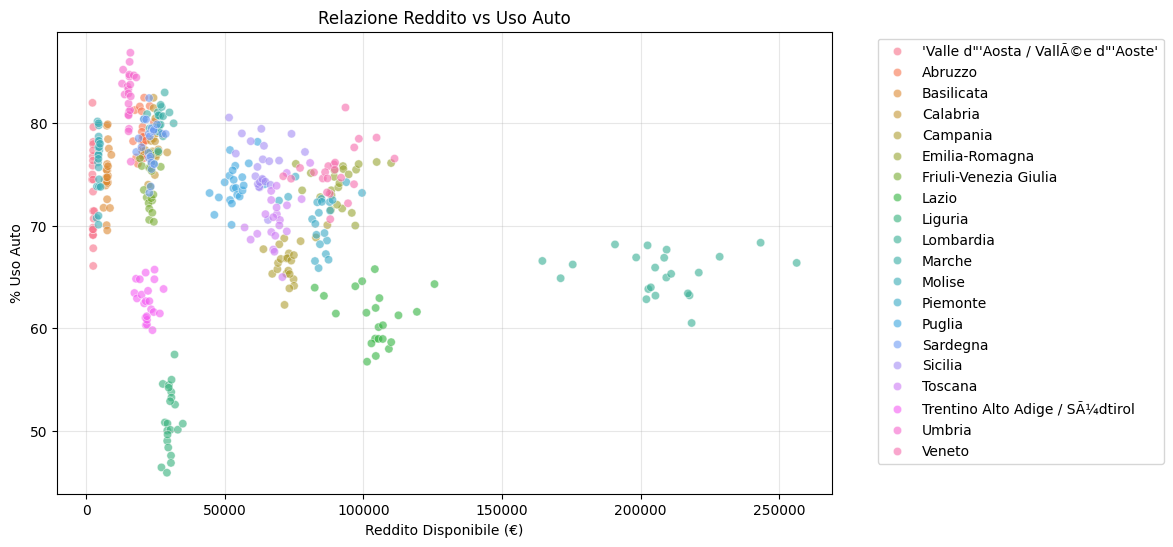

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_final_ml,
    x='Income',
    y='Perc_Auto',
    hue='Territorio',
    alpha=0.6
)
plt.title("Relazione Reddito vs Uso Auto")
plt.xlabel("Reddito Disponibile (€)")
plt.ylabel("% Uso Auto")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()
#non mi sembra di notare grandi risultati

#RANDOM FOREST PER OTTENERE LA FEATURE IMPORTANCE

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# PREPARAZIONE DATI REGIONALI
df_final_ml['Perc_Tempo_31+'] = ((df_final_ml['tempo_31+'] / df_final_ml['Totale_osservazioni']) * 100).round(2)
df_final_ml['Perc_Tempo_0-15'] = ((df_final_ml['tempo_0-15'] / df_final_ml['Totale_osservazioni']) * 100).round(2)
df_final_ml['Perc_Tempo_16-30'] = ((df_final_ml['tempo_16-30'] / df_final_ml['Totale_osservazioni']) * 100).round(2)

features = ['Perc_Auto', 'Perc_Moto', 'Perc_Public', 'Perc_Active', 'Income']
targets = ['Perc_Tempo_31+', 'Perc_Tempo_0-15']

# Pulizia finale
df_rf = df_final_ml.dropna(subset=features + targets).copy()

#FUNZIONE PER ADDESTRARE E VISUALIZZARE
def analizza_importanza(target_name, titolo_grafico):

    X = df_rf[features]
    y = df_rf[target_name]

    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X, y)

    # Estrazione Feature Importance
    importance = model.feature_importances_

    # Creazione DataFrame per il grafico
    df_imp = pd.DataFrame({
        'Feature': features,
        'Importance': importance
    }).sort_values(by='Importance', ascending=False)

    # Visualizzazione
    plt.figure(figsize=(10, 5))
    sns.barplot(x='Importance', y='Feature', data=df_imp, palette='viridis')
    plt.title(titolo_grafico)
    plt.xlabel('Feature Weight (0-1)')
    plt.show()

    # R^2 per capire quanto è affidabile il modello
    score = model.score(X, y)
    print(f"Affidabilità del modello (R^2): {score:.2f}")
    return df_imp


/tmp/ipython-input-1535384656.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_imp, palette='viridis')


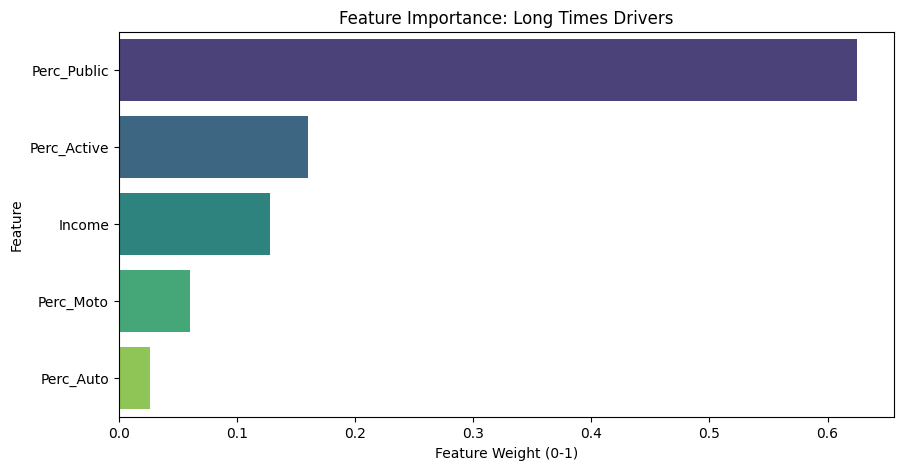

Affidabilità del modello (R^2): 0.98


In [ ]:

imp_long = analizza_importanza('Perc_Tempo_31+', 'Feature Importance: Long Times Drivers')

/tmp/ipython-input-1535384656.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=df_imp, palette='viridis')


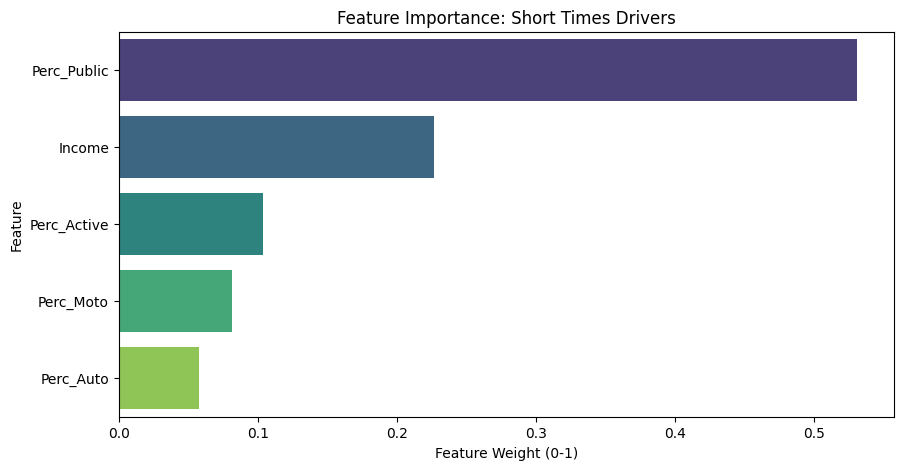

Affidabilità del modello (R^2): 0.96


In [ ]:

imp_short = analizza_importanza('Perc_Tempo_0-15', 'Feature Importance: Short Times Drivers')

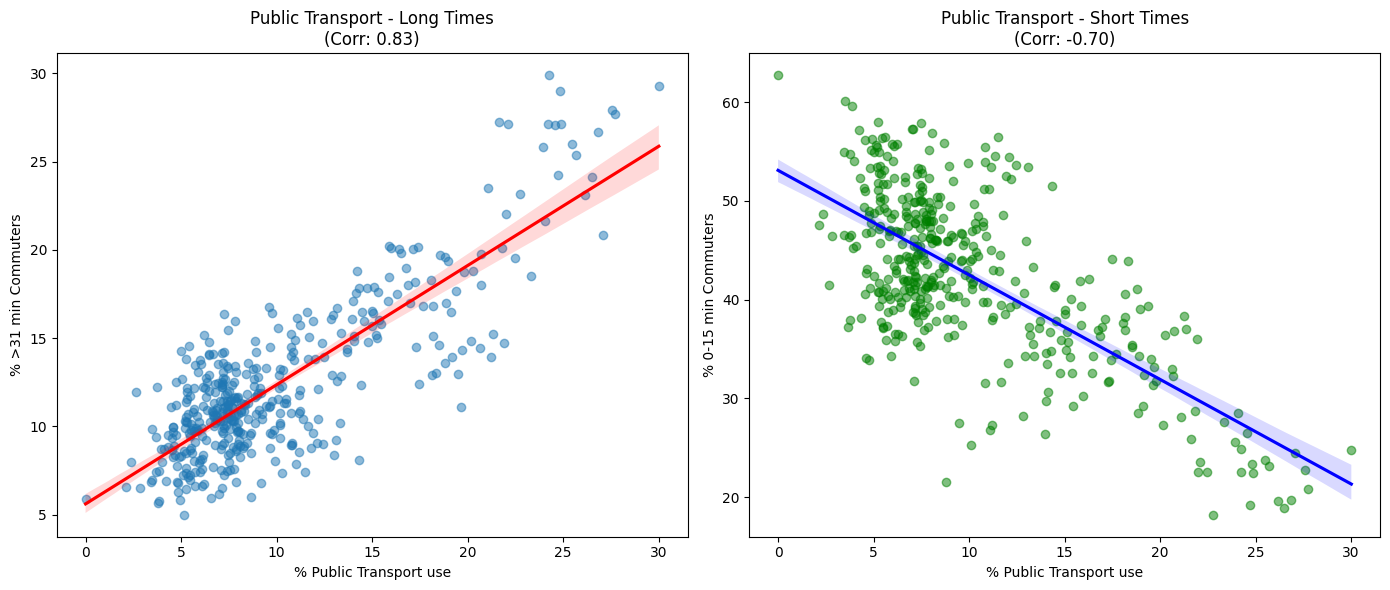

In [ ]:
import scipy.stats as stats

# Calcoliamo la correlazione di Pearson
corr_lunga = df_rf['Perc_Public'].corr(df_rf['Perc_Tempo_31+'])
corr_corta = df_rf['Perc_Public'].corr(df_rf['Perc_Tempo_0-15'])

plt.figure(figsize=(14, 6))

# Grafico 1: Mezzi vs Tempi Lunghi
plt.subplot(1, 2, 1)
sns.regplot(x='Perc_Public', y='Perc_Tempo_31+', data=df_rf,
            scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Public Transport - Long Times\n(Corr: {corr_lunga:.2f})')
plt.xlabel('% Public Transport use')
plt.ylabel('% >31 min Commuters')

# Grafico 2: Mezzi vs Tempi Corti
plt.subplot(1, 2, 2)
sns.regplot(x='Perc_Public', y='Perc_Tempo_0-15', data=df_rf,
            scatter_kws={'alpha':0.5, 'color':'green'}, line_kws={'color':'blue'})
plt.title(f'Public Transport - Short Times\n(Corr: {corr_corta:.2f})')
plt.xlabel('% Public Transport use')
plt.ylabel('% 0-15 min Commuters')

plt.tight_layout()
plt.show()

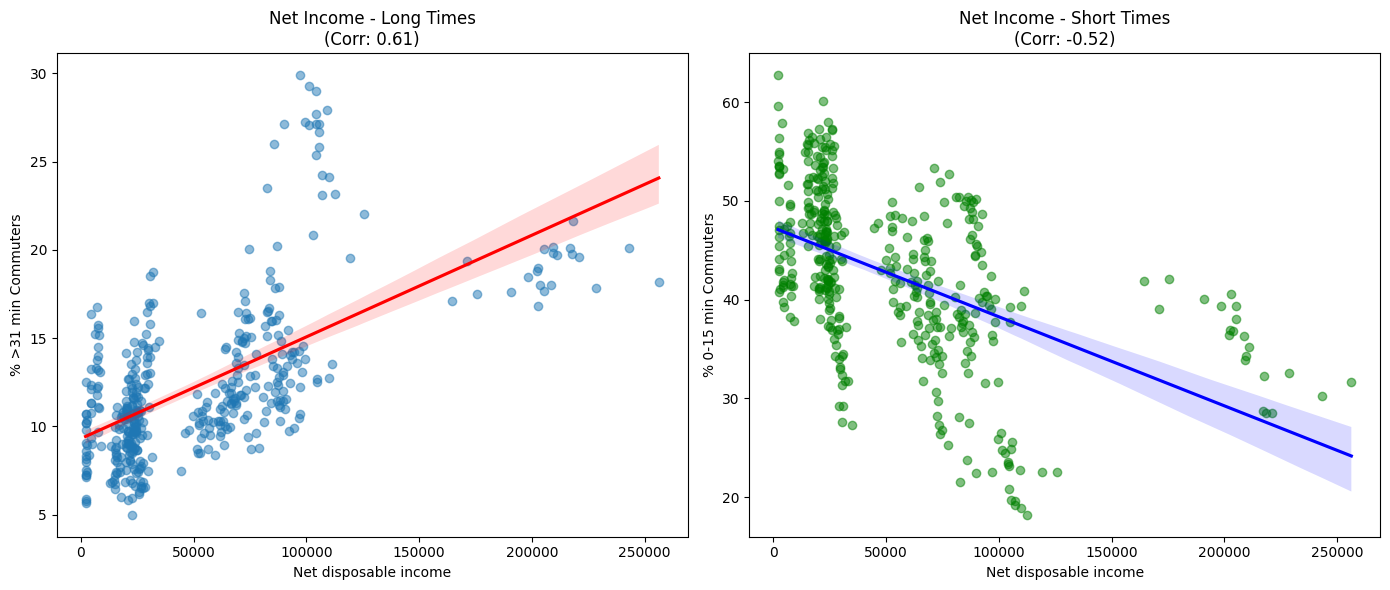

In [ ]:
import scipy.stats as stats

# Calcoliamo la correlazione di Pearson
corr_lunga1 = df_rf['Income'].corr(df_rf['Perc_Tempo_31+'])
corr_corta1 = df_rf['Income'].corr(df_rf['Perc_Tempo_0-15'])

plt.figure(figsize=(14, 6))

# Grafico 1: reddito vs Tempi Lunghi
plt.subplot(1, 2, 1)
sns.regplot(x='Income', y='Perc_Tempo_31+', data=df_rf,
            scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Net Income - Long Times\n(Corr: {corr_lunga1:.2f})')
plt.xlabel('Net disposable income')
plt.ylabel('% >31 min Commuters')

# Grafico 2: reddito vs Tempi Corti
plt.subplot(1, 2, 2)
sns.regplot(x='Income', y='Perc_Tempo_0-15', data=df_rf,
            scatter_kws={'alpha':0.5, 'color':'green'}, line_kws={'color':'blue'})
plt.title(f'Net Income - Short Times\n(Corr: {corr_corta1:.2f})')
plt.xlabel('Net disposable income')
plt.ylabel('% 0-15 min Commuters')

plt.tight_layout()
plt.show()

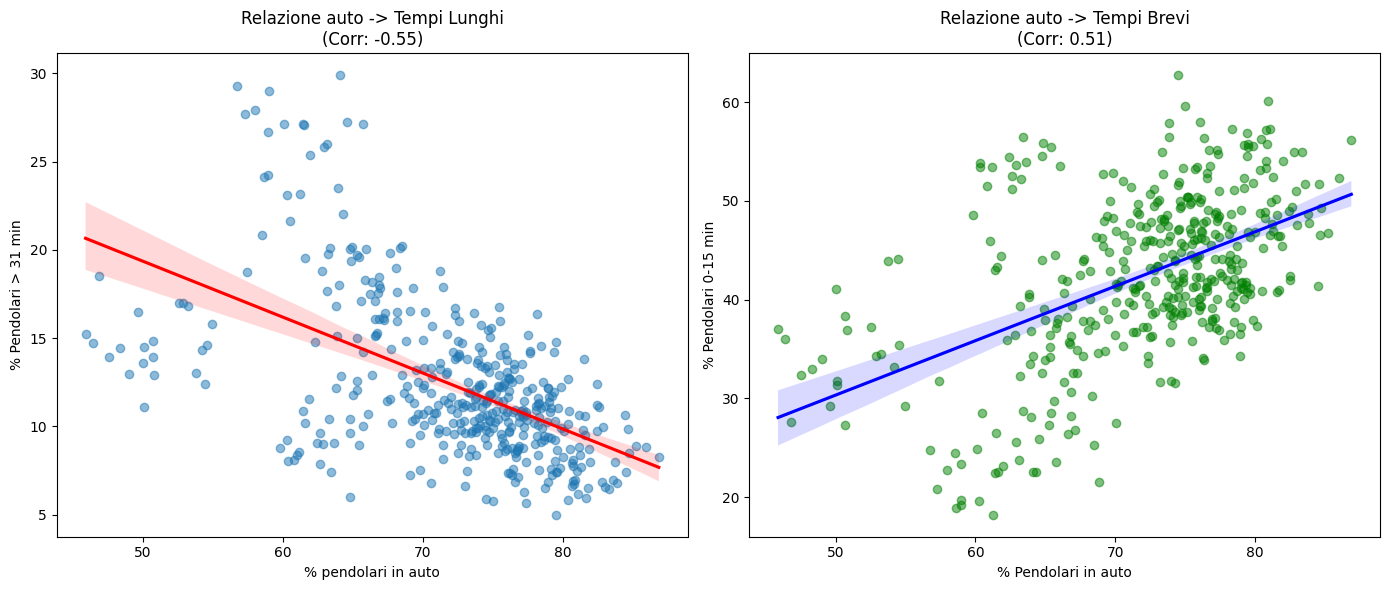

In [ ]:
import scipy.stats as stats

# Calcoliamo la correlazione di Pearson
corr_lunga1 = df_rf['Perc_Auto'].corr(df_rf['Perc_Tempo_31+'])
corr_corta1 = df_rf['Perc_Auto'].corr(df_rf['Perc_Tempo_0-15'])

plt.figure(figsize=(14, 6))

# Grafico 1: auto vs Tempi Lunghi
plt.subplot(1, 2, 1)
sns.regplot(x='Perc_Auto', y='Perc_Tempo_31+', data=df_rf,
            scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Relazione auto -> Tempi Lunghi\n(Corr: {corr_lunga1:.2f})')
plt.xlabel('% pendolari in auto')
plt.ylabel('% Pendolari > 31 min')

# Grafico 2: auto vs Tempi Corti
plt.subplot(1, 2, 2)
sns.regplot(x='Perc_Auto', y='Perc_Tempo_0-15', data=df_rf,
            scatter_kws={'alpha':0.5, 'color':'green'}, line_kws={'color':'blue'})
plt.title(f'Relazione auto -> Tempi Brevi\n(Corr: {corr_corta1:.2f})')
plt.xlabel('% Pendolari in auto')
plt.ylabel('% Pendolari 0-15 min')

plt.tight_layout()
plt.show()

,Feature,Coefficiente
0,Perc_Public,3.420766
3,Income,0.991165
2,Perc_Moto,-0.644686
1,Perc_Active,-0.707292


/tmp/ipython-input-3136229207.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)


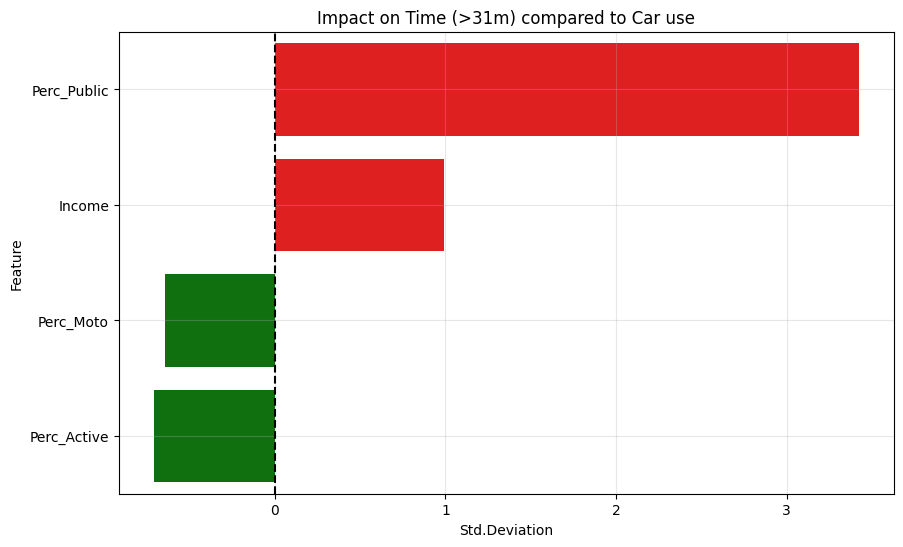

In [ ]:
from sklearn.linear_model import LinearRegression

# RIMUOVO 'Perc_Auto' dalle features.
# L'Auto diventa il Baseline
features_clean = ['Perc_Public', 'Perc_Active', 'Perc_Moto', 'Income']
target = 'Perc_Tempo_31+'

# Pulizia dati
df_reg = df_rf.dropna(subset=features_clean + [target]).copy()

#REGRESSIONE STANDARDIZZATA ---
scaler = StandardScaler()

# Scaliamo X
X = df_reg[features_clean]
X_scaled = scaler.fit_transform(X)
y = df_reg[target]

# Fit modello
lr = LinearRegression()
lr.fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features_clean,
    'Coefficiente': lr.coef_
}).sort_values(by='Coefficiente', ascending=False)
display(coef_df)

plt.figure(figsize=(10, 6))
colors = ['red' if c > 0 else 'green' for c in coef_df['Coefficiente']]

sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)

plt.title('Impact on Time (>31m) compared to Car use')
plt.xlabel('Std.Deviation')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()


tutto è relativo all'uso dell'Auto

Interpretazione dei Coefficienti
1. Perc_Public (+3.42): Il "Costo Temporale" del Mezzo Pubblico
Dato: È il coefficiente più alto in assoluto (più del triplo del reddito).

A parità di reddito, passare dall'uso dell'auto all'uso dei mezzi pubblici aumenta drasticamente la probabilità di impiegare più di 30 minuti.

Questo coefficiente quantifica l'inefficienza strutturale o la "frizione" del trasporto pubblico italiano (tempi di attesa, cambi, tratte a piedi verso le fermate)

2. Income (+0.99)

All'aumentare del reddito (tenendo fermo il mezzo di trasporto), i tempi di percorrenza aumentano.

Questo conferma la teoria della suburbanizzazione. Le persone più ricche tendono a vivere in quartieri residenziali più verdi o villette fuori dal centro caotico, accettando di viaggiare di più pur di avere una qualità abitativa migliore

3. Perc_Active (-0.71) e Perc_Moto (-0.64): La Mobilità di Prossimità e Agilità
Dato: Coefficienti negativi.

Interpretazione: Rispetto all'auto, muoversi a piedi/bici o in moto riduce il rischio di restare nel traffico per oltre 30 minuti.
È logico (nessuno cammina per 30 minuti per andare a lavoro, quindi chi va a piedi vive vicino).

Moto: Questo è interessante. La moto è l'unico mezzo a motore che "batte" l'auto sui tempi lunghi, probabilmente grazie alla capacità di evitare la congestione (filtering nel traffico).

,Feature,Coefficiente
1,Perc_Active,0.861724
2,Perc_Moto,-0.085059
3,Income,-1.779717
0,Perc_Public,-4.789931


/tmp/ipython-input-3131948415.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)


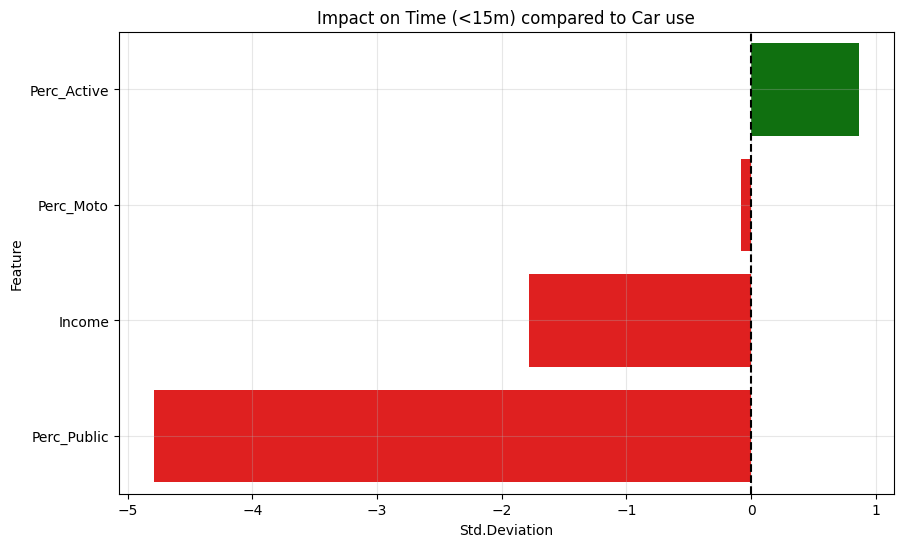

In [ ]:
features_clean = ['Perc_Public', 'Perc_Active', 'Perc_Moto', 'Income']
target = 'Perc_Tempo_0-15'

# Pulizia dati
df_reg = df_rf.dropna(subset=features_clean + [target]).copy()

# REGRESSIONE STANDARDIZZATA
scaler = StandardScaler()

# Scaliamo X
X = df_reg[features_clean]
X_scaled = scaler.fit_transform(X)
y = df_reg[target]

# Fit modello
lr = LinearRegression()
lr.fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features_clean,
    'Coefficiente': lr.coef_
}).sort_values(by='Coefficiente', ascending=False)
display(coef_df)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in coef_df['Coefficiente']]

sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)

plt.title('Impact on Time (<15m) compared to Car use')
plt.xlabel('Std.Deviation')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()


1. Trasporto Pubblico (-4.8): L'Incompatibilità Strutturale col Breve tempo
Coefficiente fortissimamente negativo.
Nessuno prende l'autobus per fare 1 km (ci mette più tempo ad aspettarlo che ad andare a piedi o in auto). Se usi i mezzi, è quasi certo che il tuo viaggio durerà almeno 20-30 minuti.

L'auto (baseline) viene usata spessissimo anche per tragitti(scuola-casa, spesa sotto casa) che durano meno di 15 minuti. Il mezzo pubblico no. Ecco perché il coefficiente crolla.

2. Reddito (-1.8): Coefficiente negativo molto netto.
Più si alza il reddito, più diminuisce la probabilità di avere un tragitto breve (0-15 min).

Dato molto interessante: probabilmente dovuto al fatto che i ceti meno abbienti spesso vivono e lavorano nello stesso quartiere o accettano lavori di prossimità. I ceti più ricchi lavorano spesso nei centri direzionali (o grandi poli industriali) ma vivono nel verde o in quartieri residenziali distanti, rendendo il viaggio "sotto i 15 minuti" una rarità statistica per loro.

3. la Moto (-0.085): coefficiente negativo sui lunghi, e leggermente negativo (quasi zero) sui corti.

dunque la maggior parte dei motociclisti si trova nella fascia 16-30 minuti.
lo si puo spiegare considerando che per fare 500 metri non ti metti casco, guanti e accendi la moto. Prendi l'auto (più comoda) o vai a piedi. Quindi la moto è meno probabile dell'auto sui brevissimi tratti (da qui il leggero -0.08).

vs Lunghi: La moto ti permette di "tagliare" il traffico. Un viaggio che in auto diventerebbe "Lungo" (40 min in coda), in moto rientra nei 25 minuti. La moto comprime i tempi lunghi facendoli diventare medi.

#regressione tenendo conto anche delle variabili binarie di tipo territorio e interseco con le percentuali dei mezzi (no reddito)

/tmp/ipython-input-2952572337.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_urb, palette='magma')


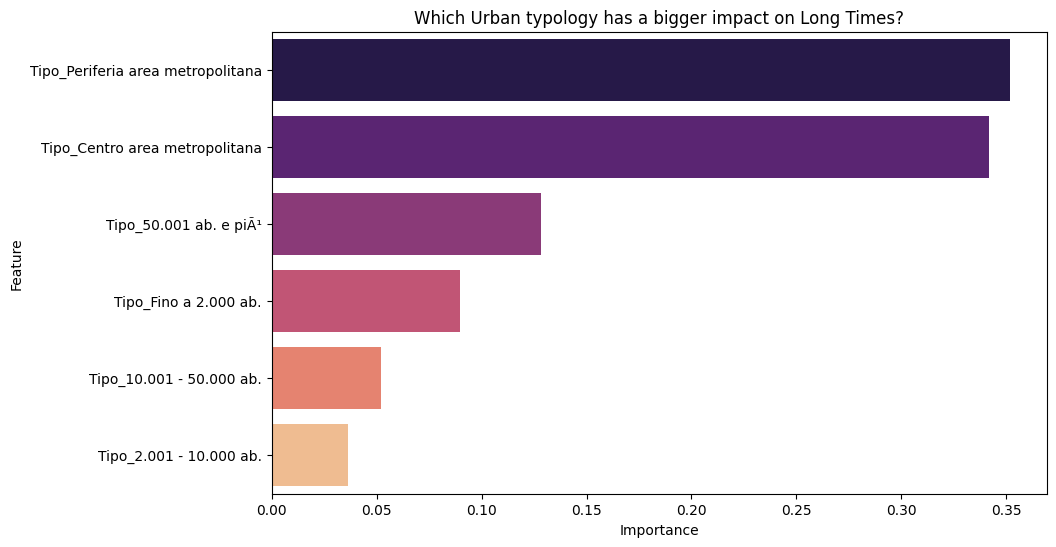

In [ ]:
# PREPARAZIONE DATI URBANI
df_urban_ml = df_analysis.copy()

# 1. ONE-HOT ENCODING, Trasforma la colonna 'Territorio' in colonne separate
df_encoded = pd.get_dummies(df_urban_ml, columns=['Territorio'], prefix='Tipo')

features_urban = [col for col in df_encoded.columns if col.startswith('Tipo_')]

target_urban = 'Perc_Tempo_31_plus'

# Pulizia
df_encoded = df_encoded.dropna(subset=features_urban + [target_urban])

#RANDOM FOREST SULLE TIPOLOGIE URBANE
X_urb = df_encoded[features_urban]
y_urb = df_encoded[target_urban]

model_urb = RandomForestRegressor(n_estimators=100, random_state=42)
model_urb.fit(X_urb, y_urb)

importance_urb = pd.DataFrame({
    'Feature': features_urban,
    'Importance': model_urb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_urb, palette='magma')
plt.title('Which Urban typology has a bigger impact on Long Times?')
plt.xlabel('Importance')
plt.show()


/tmp/ipython-input-3418658181.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_urb, palette='magma')


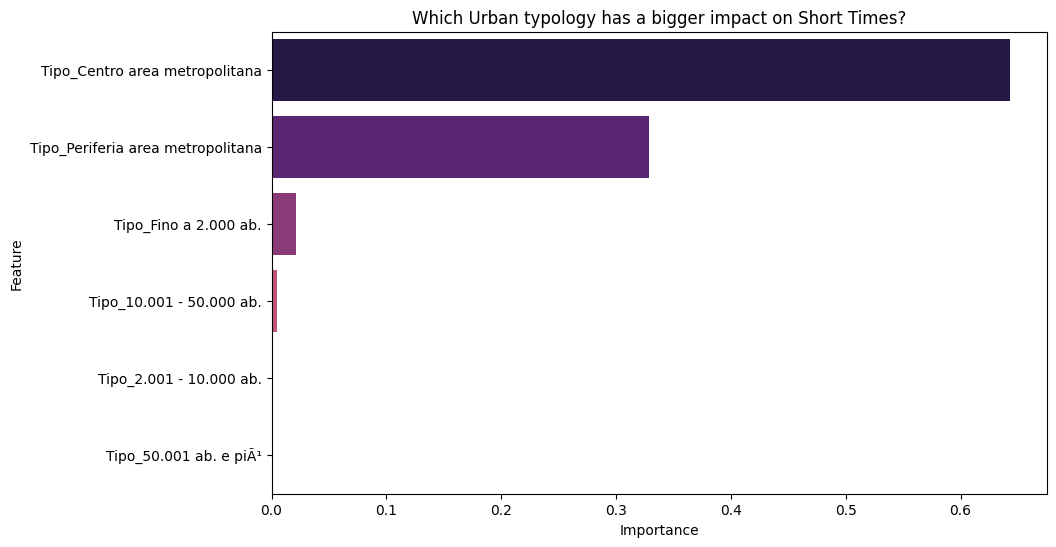

In [ ]:
#tempi corti
target_urban = 'Perc_Tempo_0_15'

# Pulizia
df_encoded = df_encoded.dropna(subset=features_urban + [target_urban])

# RANDOM FOREST SULLE TIPOLOGIE URBANE
X_urb = df_encoded[features_urban]
y_urb = df_encoded[target_urban]

model_urb = RandomForestRegressor(n_estimators=100, random_state=42)
model_urb.fit(X_urb, y_urb)

importance_urb = pd.DataFrame({
    'Feature': features_urban,
    'Importance': model_urb.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_urb, palette='magma')
plt.title('Which Urban typology has a bigger impact on Short Times?')
plt.xlabel('Importance')
plt.show()

,Feature,Coefficiente
0,Perc_Public_Transport,2.181933
8,Tipo_Periferia area metropolitana,1.726444
7,Tipo_Fino a 2.000 ab.,0.778183
2,Perc_Moto,0.380140
6,Tipo_Centro area metropolitana,0.291833
4,Tipo_2.001 - 10.000 ab.,-0.162200
1,Perc_Active_Mobility,-0.398745
3,Tipo_10.001 - 50.000 ab.,-0.872671
5,Tipo_50.001 ab. e piÃ¹,-1.761589


/tmp/ipython-input-130652065.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)


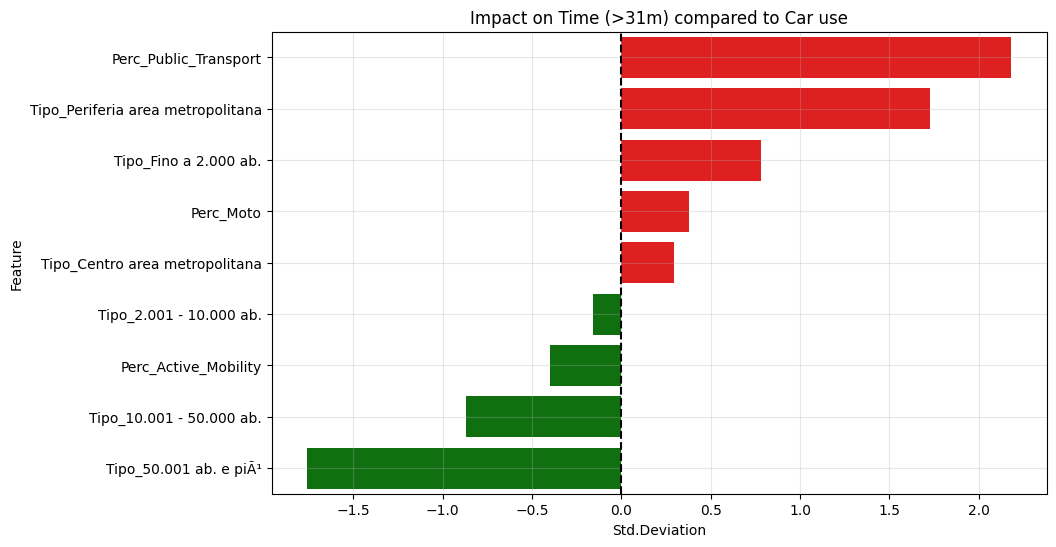

R^2 Score: 0.92


In [ ]:
# sempre con l'auto come baseline
features_clean = ['Perc_Public_Transport', 'Perc_Active_Mobility', 'Perc_Moto', 'Tipo_10.001 - 50.000 ab.', 'Tipo_2.001 - 10.000 ab.', 'Tipo_50.001 ab. e piÃ¹', 'Tipo_Centro area metropolitana',
 'Tipo_Fino a 2.000 ab.', 'Tipo_Periferia area metropolitana']

target = 'Perc_Tempo_31_plus'

# Pulizia dati
df_terr = df_encoded.dropna(subset=features_clean + [target]).copy()

#REGRESSIONE STANDARDIZZATA
scaler = StandardScaler()

# Scaliamo X
X = df_terr[features_clean]
X_scaled = scaler.fit_transform(X)
y = df_terr[target]

# Fit modello
lr = LinearRegression()
lr.fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features_clean,
    'Coefficiente': lr.coef_
}).sort_values(by='Coefficiente', ascending=False)
display(coef_df)

plt.figure(figsize=(10, 6))
colors = ['red' if c > 0 else 'green' for c in coef_df['Coefficiente']]

sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)

plt.title('Impact on Time (>31m) compared to Car use')
plt.xlabel('Std.Deviation')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

print(f"R^2 Score: {lr.score(X_scaled, y):.2f}")

,Feature,Coefficiente
2,Perc_Moto,6.113340
3,Tipo_10.001 - 50.000 ab.,4.530534
4,Tipo_2.001 - 10.000 ab.,4.333303
7,Tipo_Fino a 2.000 ab.,3.885022
5,Tipo_50.001 ab. e piÃ¹,1.848915
0,Perc_Public_Transport,1.183992
1,Perc_Active_Mobility,0.256496
8,Tipo_Periferia area metropolitana,-2.825108
6,Tipo_Centro area metropolitana,-11.772665


/tmp/ipython-input-386807086.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)


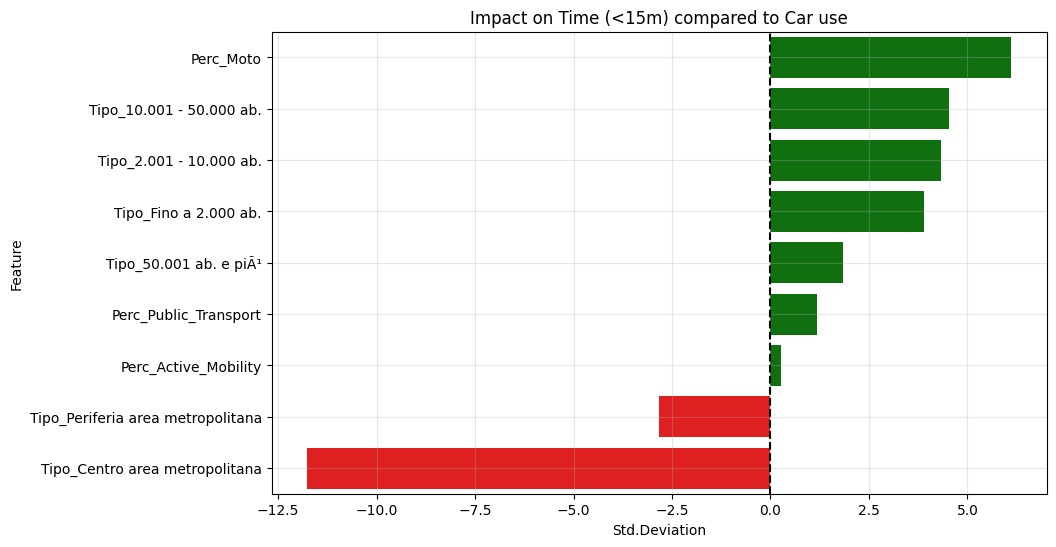

R^2 Score: 0.88


In [ ]:
# tempi corti
features_clean = ['Perc_Public_Transport', 'Perc_Active_Mobility', 'Perc_Moto', 'Tipo_10.001 - 50.000 ab.', 'Tipo_2.001 - 10.000 ab.', 'Tipo_50.001 ab. e piÃ¹', 'Tipo_Centro area metropolitana',
 'Tipo_Fino a 2.000 ab.', 'Tipo_Periferia area metropolitana']

target = 'Perc_Tempo_0_15'

# Pulizia dati
df_terr = df_encoded.dropna(subset=features_clean + [target]).copy()

# REGRESSIONE STANDARDIZZATA
scaler = StandardScaler()

# Scaliamo X
X = df_terr[features_clean]
X_scaled = scaler.fit_transform(X)
y = df_terr[target]

# Fit modello
lr = LinearRegression()
lr.fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features_clean,
    'Coefficiente': lr.coef_
}).sort_values(by='Coefficiente', ascending=False)
display(coef_df)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in coef_df['Coefficiente']]

sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)

plt.title('Impact on Time (<15m) compared to Car use')
plt.xlabel('Std.Deviation')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

print(f"R^2 Score: {lr.score(X_scaled, y):.2f}")

da notare che in quello precedente erano importanti i mezzi pubblici, mentre qui lo è la zona centro_area_metropolitana

,Feature,Coefficiente
6,Tipo_Centro area metropolitana,11.502814
8,Tipo_Periferia area metropolitana,1.096539
1,Perc_Active_Mobility,0.143769
5,Tipo_50.001 ab. e piÃ¹,-0.086814
0,Perc_Public_Transport,-3.378976
3,Tipo_10.001 - 50.000 ab.,-3.666703
4,Tipo_2.001 - 10.000 ab.,-4.179367
7,Tipo_Fino a 2.000 ab.,-4.666469
2,Perc_Moto,-6.512998


/tmp/ipython-input-1211568114.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)


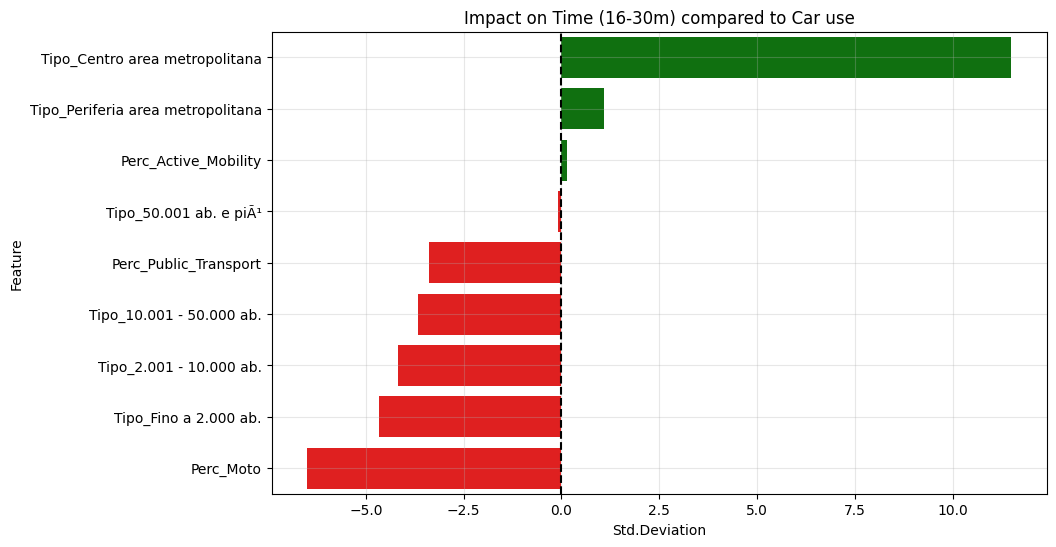

R^2 Score: 0.76


In [ ]:
#tempi medi
features_clean = ['Perc_Public_Transport', 'Perc_Active_Mobility', 'Perc_Moto', 'Tipo_10.001 - 50.000 ab.', 'Tipo_2.001 - 10.000 ab.', 'Tipo_50.001 ab. e piÃ¹', 'Tipo_Centro area metropolitana',
 'Tipo_Fino a 2.000 ab.', 'Tipo_Periferia area metropolitana']

target = 'Perc_Tempo_16_30'

# Pulizia dati
df_terr = df_encoded.dropna(subset=features_clean + [target]).copy()

# REGRESSIONE STANDARDIZZATA
scaler = StandardScaler()

# Scaliamo X
X = df_terr[features_clean]
X_scaled = scaler.fit_transform(X)
y = df_terr[target]

# Fit modello
lr = LinearRegression()
lr.fit(X_scaled, y)

coef_df = pd.DataFrame({
    'Feature': features_clean,
    'Coefficiente': lr.coef_
}).sort_values(by='Coefficiente', ascending=False)
display(coef_df)

plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in coef_df['Coefficiente']]

sns.barplot(x='Coefficiente', y='Feature', data=coef_df, palette=colors)

plt.title('Impact on Time (16-30m) compared to Car use')
plt.xlabel('Std.Deviation')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

print(f"R^2 Score: {lr.score(X_scaled, y):.2f}")

In [ ]:
df_encoded

,TIME_PERIOD,tempo_31+,Auto_Conducente,Auto_Passeggero,Bici,tempo_0-15,Metro,Moto,Pullman_Aziendale,Pullman,...,Perc_Tempo_0_15,Perc_Tempo_16_30,Perc_Tempo_31_plus,Cluster,Tipo_10.001 - 50.000 ab.,Tipo_2.001 - 10.000 ab.,Tipo_50.001 ab. e piÃ¹,Tipo_Centro area metropolitana,Tipo_Fino a 2.000 ab.,Tipo_Periferia area metropolitana
23,2001,582,3563,334,131.0,2654,27.0,132.0,45.0,110.0,...,51.5,37.2,11.3,1,True,False,False,False,False,False
24,2002,556,3818,322,170.0,2887,28.0,155.0,45.0,96.0,...,52.5,37.3,10.1,1,True,False,False,False,False,False
25,2003,571,3921,286,165.0,2891,49.0,235.0,64.0,83.0,...,51.5,38.3,10.2,1,True,False,False,False,False,False
26,2005,630,3920,346,193.0,2820,63.0,137.0,58.0,106.0,...,50.0,38.8,11.2,1,True,False,False,False,False,False
27,2006,758,4075,338,186.0,2883,68.0,150.0,39.0,95.0,...,50.1,36.7,13.2,1,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
432,2020,719,2290,146,73.0,922,201.0,107.0,2.0,104.0,...,26.3,53.1,20.5,2,False,False,False,False,False,True
433,2021,668,2266,142,65.0,821,114.0,108.0,6.0,70.0,...,24.9,54.8,20.3,2,False,False,False,False,False,True
434,2022,649,2353,139,72.0,1009,121.0,72.0,6.0,71.0,...,29.8,51.1,19.1,2,False,False,False,False,False,True
435,2023,561,2410,160,71.0,988,120.0,68.0,6.0,100.0,...,29.0,54.6,16.5,2,False,False,False,False,False,True


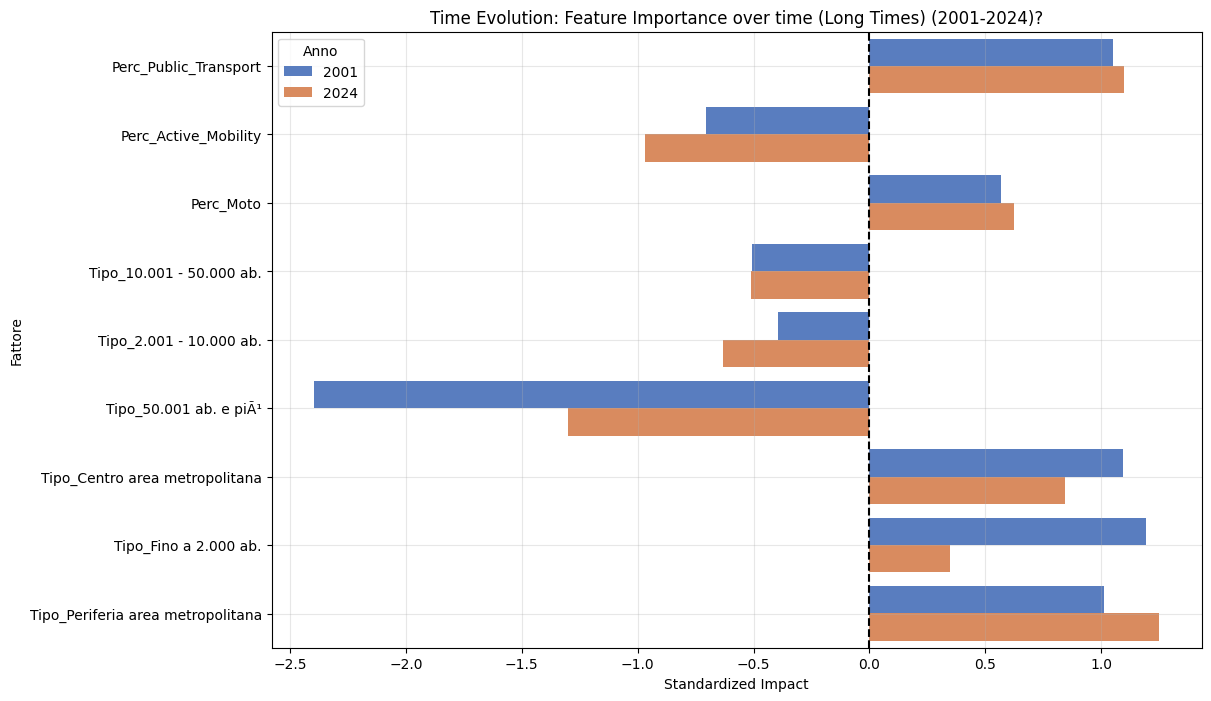

In [ ]:
df_step2=df_encoded.copy()
features_mix=features_clean
# --- CONFRONTO TEMPORALE: 2001 vs 2024

#  Filering sui due anni estremi
anno_inizio = df_step2['TIME_PERIOD'].min()
anno_fine = df_step2['TIME_PERIOD'].max()

target = 'Perc_Tempo_31_plus'
# Funzione per estrarre i coefficienti di un anno specifico
def get_coeffs_by_year(year):
    df_year = df_step2[df_step2['TIME_PERIOD'] == year].copy()

    # Standardizzazione
    scaler = StandardScaler()
    X = scaler.fit_transform(df_year[features_mix]) # Usa le stesse feature 'mix' di prima
    y = df_year[target]

    # Regressione
    lr = LinearRegression()
    lr.fit(X, y)

    return pd.DataFrame({
        'Fattore': features_mix,
        'Impatto': lr.coef_,
        'Anno': str(year)
    })

# calcolo
df_coeffs_start = get_coeffs_by_year(anno_inizio)
df_coeffs_end = get_coeffs_by_year(anno_fine)

# Unione dei risultati
df_compare = pd.concat([df_coeffs_start, df_coeffs_end])

plt.figure(figsize=(12, 8))
sns.barplot(x='Impatto', y='Fattore', hue='Anno', data=df_compare, palette='muted')
plt.title(f'Time Evolution: Feature Importance over time (Long Times) ({anno_inizio}-{anno_fine})?')
plt.xlabel('Standardized Impact')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

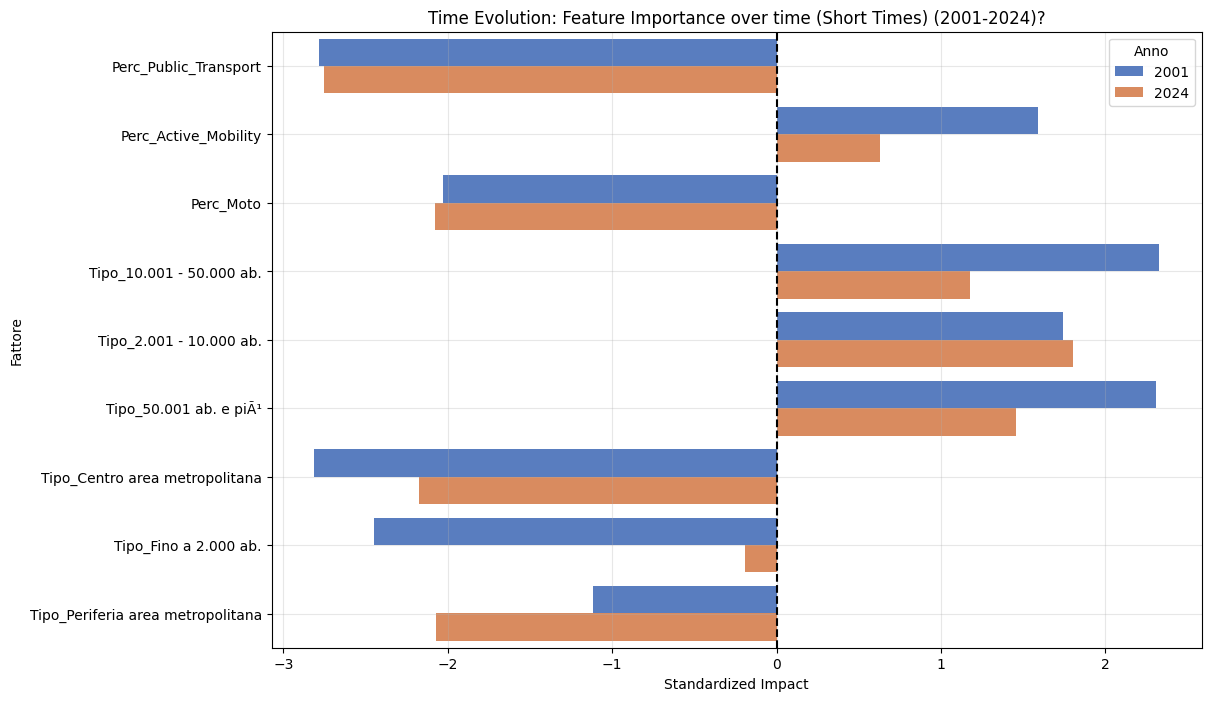

In [ ]:
target = 'Perc_Tempo_0_15'
df_coeffs_start = get_coeffs_by_year(anno_inizio)
df_coeffs_end = get_coeffs_by_year(anno_fine)

# Unione dei risultati
df_compare = pd.concat([df_coeffs_start, df_coeffs_end])

plt.figure(figsize=(12, 8))
sns.barplot(x='Impatto', y='Fattore', hue='Anno', data=df_compare, palette='muted')
plt.title(f'Time Evolution: Feature Importance over time (Short Times) ({anno_inizio}-{anno_fine})?')
plt.xlabel('Standardized Impact')
plt.axvline(x=0, color='black', linestyle='--')
plt.grid(True, alpha=0.3)
plt.show()

#classificazione logistica (MACHINE LEARNING)

In [ ]:
features_mix

['Perc_Public_Transport',
 'Perc_Active_Mobility',
 'Perc_Moto',
 'Tipo_10.001 - 50.000 ab.',
 'Tipo_2.001 - 10.000 ab.',
 'Tipo_50.001 ab. e piÃ¹',
 'Tipo_Centro area metropolitana',
 'Tipo_Fino a 2.000 ab.',
 'Tipo_Periferia area metropolitana']

In [ ]:
features_mix.append('Perc_Auto')

"Per l'analisi di classificazione sulle Aree Urbane, ho scelto di includere sia le variabili territoriali che quelle comportamentali (mezzi) .Qui l'obiettivo è capire come le abitudini di mobilità interagiscono con la struttura della città, per fornire indicazioni utili alle politiche di mobilità sostenibile."

Soglia di criticità = 14.4%
              precision    recall  f1-score   support

           0       1.00      0.89      0.94        18
           1       0.83      1.00      0.91        10

    accuracy                           0.93        28
   macro avg       0.92      0.94      0.93        28
weighted avg       0.94      0.93      0.93        28



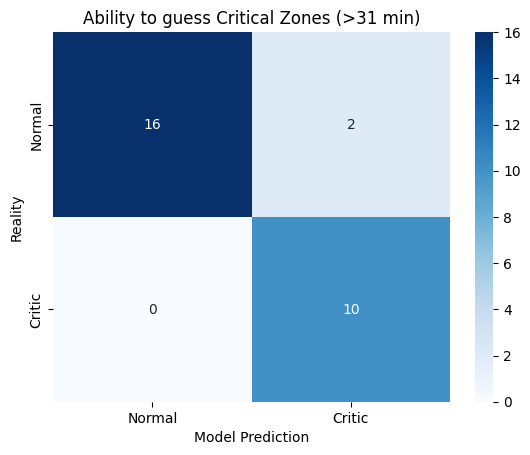

,Feature,Coeff,Odds_Ratio
0,Perc_Public_Transport,1.029098,2.798540
8,Tipo_Periferia area metropolitana,1.028433,2.796680
7,Tipo_Fino a 2.000 ab.,0.762417,2.143452
6,Tipo_Centro area metropolitana,0.660297,1.935366
4,Tipo_2.001 - 10.000 ab.,-0.140755,0.868702
1,Perc_Active_Mobility,-0.356566,0.700077
2,Perc_Moto,-0.483275,0.616760
9,Perc_Auto,-0.630793,0.532169
5,Tipo_50.001 ab. e piÃ¹,-1.137172,0.320725
3,Tipo_10.001 - 50.000 ab.,-1.173221,0.309369


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Una zona è critica se più della metà dei pendolari ci mette >30 min
soglia_critica = df_step2['Perc_Tempo_31_plus'].median()
print(f"Soglia di criticità = {soglia_critica:.1f}%")

df_class = df_step2.copy()
df_class['Status_Critico'] = (df_class['Perc_Tempo_31_plus'] > soglia_critica).astype(int)

# LOGISTIC REGRESSION ---
# Feature: Uso Mezzi + Zone
X = df_class[features_mix]
y = df_class['Status_Critico']

# Scaling (Obbligatorio per la Logistica)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split Train/Test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Modello
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print(classification_report(y_test, y_pred))

# quanti Falsi positivi e Falsi negativi
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Critic'], yticklabels=['Normal', 'Critic'])
plt.ylabel('Reality')
plt.xlabel('Model Prediction')
plt.title('Ability to guess Critical Zones (>31 min)')
plt.show()

# Vediamo come aumenta la probabilità di essere "Critici" all'aumentare dei coefficienti
# anche odds ratio
coefs = pd.DataFrame({'Feature': features_mix, 'Coeff': log_reg.coef_[0]})
coefs['Odds_Ratio'] = np.exp(coefs['Coeff']) # Quanto aumenta il rischio per ogni unità in più
display(coefs.sort_values(by='Odds_Ratio', ascending=False))

Soglia di criticità stabilita a: 40.0%
              precision    recall  f1-score   support

           0       1.00      0.64      0.78        11
           1       0.81      1.00      0.89        17

    accuracy                           0.86        28
   macro avg       0.90      0.82      0.84        28
weighted avg       0.88      0.86      0.85        28



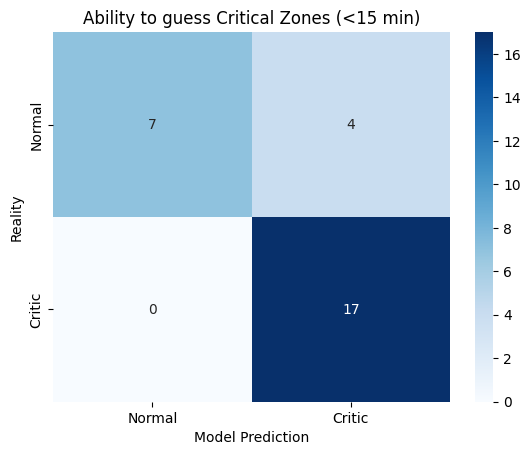

,Feature,Coeff,Odds_Ratio
3,Tipo_10.001 - 50.000 ab.,0.730743,2.076623
2,Perc_Moto,0.720653,2.055776
1,Perc_Active_Mobility,0.630505,1.878559
7,Tipo_Fino a 2.000 ab.,0.497694,1.644923
4,Tipo_2.001 - 10.000 ab.,0.487154,1.627678
5,Tipo_50.001 ab. e piÃ¹,0.362463,1.436864
9,Perc_Auto,0.147865,1.159356
0,Perc_Public_Transport,-0.564462,0.568666
8,Tipo_Periferia area metropolitana,-0.878197,0.415531
6,Tipo_Centro area metropolitana,-1.199857,0.301237


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

#tempi corti
soglia_critica = df_step2['Perc_Tempo_0_15'].median()
print(f"Soglia di criticità stabilita a: {soglia_critica:.1f}%")

df_class = df_step2.copy()
df_class['Status_Critico'] = (df_class['Perc_Tempo_0_15'] > soglia_critica).astype(int)

# LOGISTIC REGRESSION
X = df_class[features_mix]
y = df_class['Status_Critico']

# Scaling (Obbligatorio per la Logistica)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split Train/Test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Modello
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)

print(classification_report(y_test, y_pred))

# quanti Falsi positivi e Falsi negativi
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Critic'], yticklabels=['Normal', 'Critic'])
plt.ylabel('Reality')
plt.xlabel('Model Prediction')
plt.title('Ability to guess Critical Zones (<15 min)')
plt.show()

#come aumenta la probabilità di essere Critici all'aumentare dei coefficienti
# Odds Ratio anche
coefs = pd.DataFrame({'Feature': features_mix, 'Coeff': log_reg.coef_[0]})
coefs['Odds_Ratio'] = np.exp(coefs['Coeff']) # Quanto aumenta il rischio per ogni unità in più
display(coefs.sort_values(by='Odds_Ratio', ascending=False))

#stesso algoritmo di machine learning ma col dataset delle regioni e reddito: è possibile classificare correttamente basandosi sulle regioni invece che sul tipo di area?

A differenza dell'analisi per area urbana, in questa analisi regionale l'obiettivo e quello di isolare il rischio territoriale puro, percio non ho incluso in input le variabili relative alle percentuali dei mezzi utilizzati

              precision    recall  f1-score   support

           0       0.86      0.90      0.88        48
           1       0.87      0.82      0.85        40

    accuracy                           0.86        88
   macro avg       0.86      0.86      0.86        88
weighted avg       0.86      0.86      0.86        88



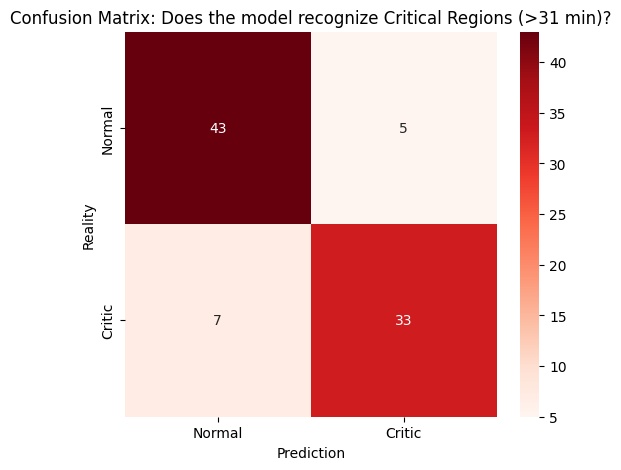

/tmp/ipython-input-1257171642.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Rischio (Odds Ratio)', y='Regione', data=coefs, palette='coolwarm')


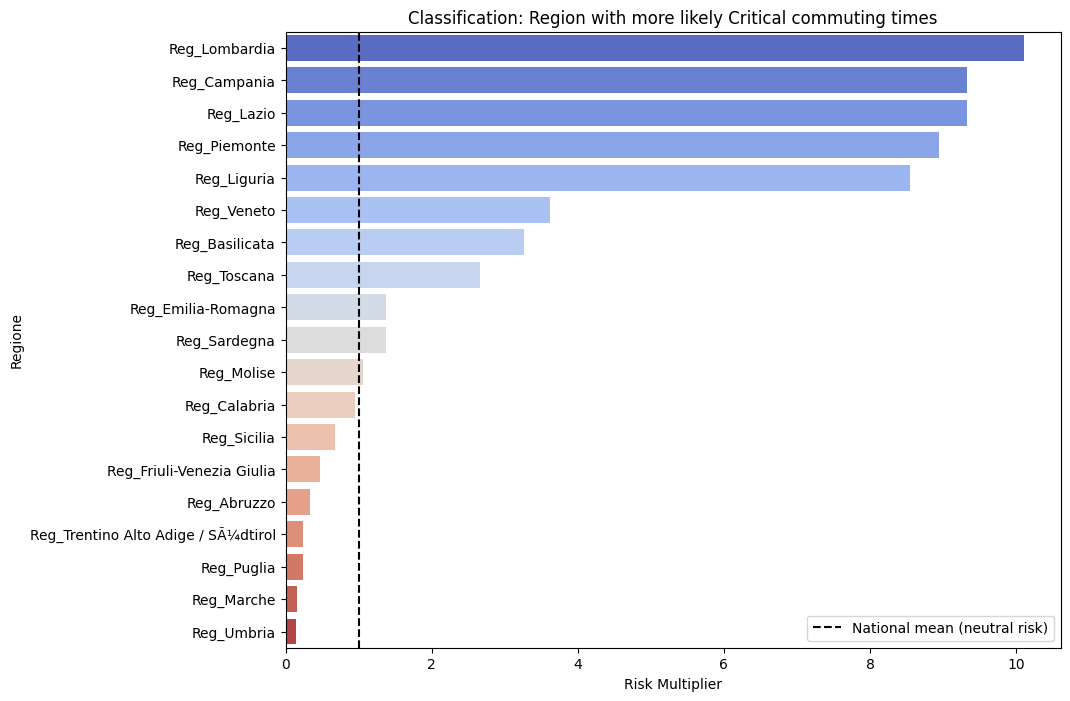

In [ ]:
#vanno create prima le variabili dummy nel dataset

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df_region_log = df_final_ml.copy()

# Uso la stessa soglia del modello urbano per confrontarli equamente (mediana)
soglia_critica = df_region_log['Perc_Tempo_31+'].median()
df_region_log['Status_Critico'] = (df_region_log['Perc_Tempo_31+'] > soglia_critica).astype(int)


# One-Hot Encoding delle Regioni
# drop_first=True serve per evitare la multicollinearità (la regione esclusa diventa il riferimento base)
df_encoded_reg = pd.get_dummies(df_region_log, columns=['Territorio'], prefix='Reg', drop_first=True)

features_regioni = [col for col in df_encoded_reg.columns if col.startswith('Reg_')]

# Pulizia
df_encoded_reg = df_encoded_reg.dropna(subset=features_regioni + ['Status_Critico'])

# REGRESSIONE LOGISTICA
X = df_encoded_reg[features_regioni]
y = df_encoded_reg['Status_Critico']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modello
log_reg_region = LogisticRegression(max_iter=1000)
log_reg_region.fit(X_train, y_train)

y_pred = log_reg_region.predict(X_test)
print(classification_report(y_test, y_pred))

# Matrice di Confusione
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Normal', 'Critic'], yticklabels=['Normal', 'Critic'])
plt.title('Confusion Matrix: Does the model recognize Critical Regions (>31 min)?')
plt.ylabel('Reality')
plt.xlabel('Prediction')
plt.show()

# CLASSIFICA DEL RISCHIO (ODDS RATIO)
# Quale regione aumenta di più la probabilità di essere critica?
coefs = pd.DataFrame({
    'Regione': features_regioni,
    'Coefficiente': log_reg_region.coef_[0]
})
# L'Odds Ratio indica quante volte è più probabile essere critici qui rispetto alla media
coefs['Rischio (Odds Ratio)'] = np.exp(coefs['Coefficiente'])

coefs = coefs.sort_values(by='Rischio (Odds Ratio)', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Rischio (Odds Ratio)', y='Regione', data=coefs, palette='coolwarm')
plt.axvline(x=1, color='black', linestyle='--', label='National mean (neutral risk)')
plt.title('Classification: Region with more likely Critical commuting times')
plt.xlabel('Risk Multiplier')
plt.legend()
plt.show()

              precision    recall  f1-score   support

           0       0.74      0.57      0.64        44
           1       0.65      0.80      0.71        44

    accuracy                           0.68        88
   macro avg       0.69      0.68      0.68        88
weighted avg       0.69      0.68      0.68        88



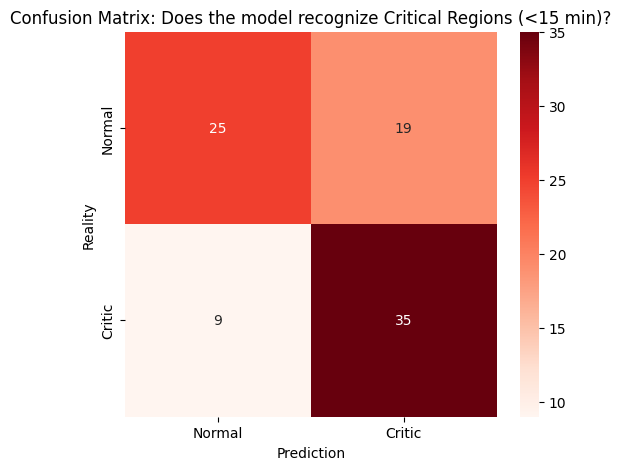

/tmp/ipython-input-2493327775.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Rischio (Odds Ratio)', y='Regione', data=coefs, palette='coolwarm')


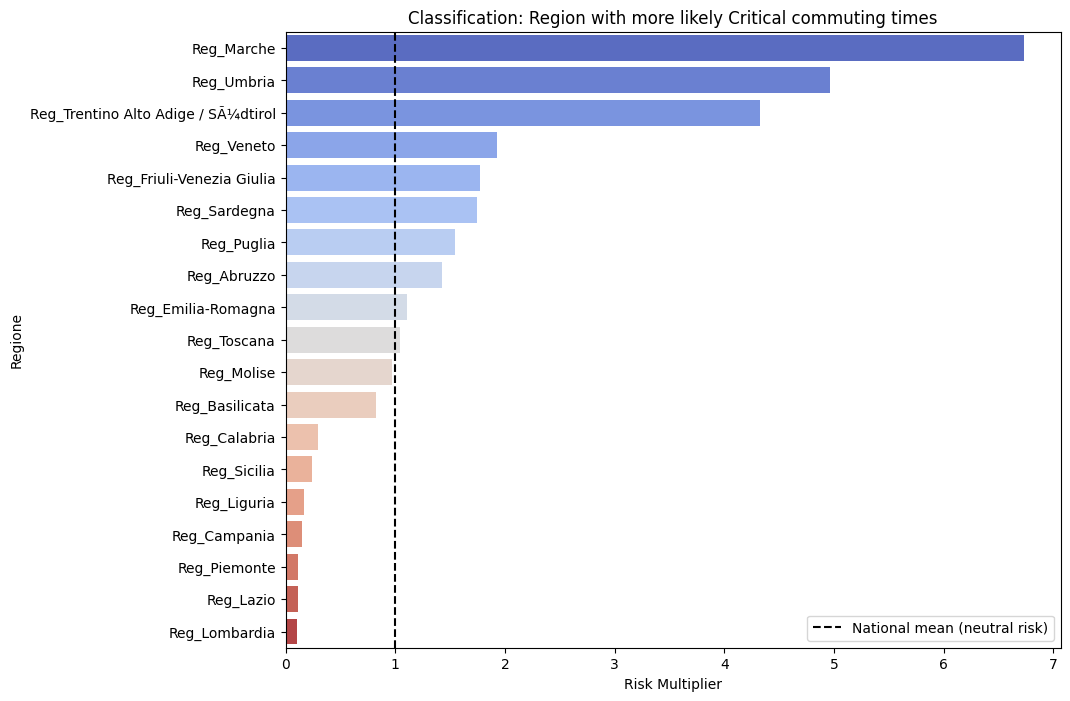

In [ ]:
#ora per tempi corti

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


soglia_critica = df_region_log['Perc_Tempo_0-15'].median()
df_region_log['Status_Critico'] = (df_region_log['Perc_Tempo_0-15'] > soglia_critica).astype(int)

# One-Hot Encoding delle Regioni
# drop_first=True evita la multicollinearità (la regione esclusa diventa il riferimento base)
df_encoded_reg = pd.get_dummies(df_region_log, columns=['Territorio'], prefix='Reg', drop_first=True)

features_regioni = [col for col in df_encoded_reg.columns if col.startswith('Reg_')]

# Pulizia
df_encoded_reg = df_encoded_reg.dropna(subset=features_regioni + ['Status_Critico'])

# REGRESSIONE LOGISTICA
X = df_encoded_reg[features_regioni]
y = df_encoded_reg['Status_Critico']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modello
log_reg_region = LogisticRegression(max_iter=1000)
log_reg_region.fit(X_train, y_train)

y_pred = log_reg_region.predict(X_test)
print(classification_report(y_test, y_pred))

# Matrice di Confusione
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Normal', 'Critic'], yticklabels=['Normal', 'Critic'])
plt.title('Confusion Matrix: Does the model recognize Critical Regions (<15 min)?')
plt.ylabel('Reality')
plt.xlabel('Prediction')
plt.show()

# CLASSIFICA DEL RISCHIO (ODDS RATIO)
# Quale regione aumenta di più la probabilità di essere critica?
coefs = pd.DataFrame({
    'Regione': features_regioni,
    'Coefficiente': log_reg_region.coef_[0]
})
# L'Odds Ratio indica quante volte è più probabile essere critici qui rispetto alla media
coefs['Rischio (Odds Ratio)'] = np.exp(coefs['Coefficiente'])

coefs = coefs.sort_values(by='Rischio (Odds Ratio)', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Rischio (Odds Ratio)', y='Regione', data=coefs, palette='coolwarm')
plt.axvline(x=1, color='black', linestyle='--', label='National mean (neutral risk)')
plt.title('Classification: Region with more likely Critical commuting times')
plt.xlabel('Risk Multiplier')
plt.legend()
plt.show()

la differenza tra l'86% e il 68% è la prova statistica di come funziona la mobilità in Italia. Il fatto che il modello indovini quasi sempre se una zona è critica basandosi solo sulla Regione significa che i ritardi sono strutturali.

Interpretazione: I tempi lunghi dipendono dalle grandi infrastrutture (o dalla loro assenza): autostrade intasate, linee ferroviarie regionali inefficienti, geografia montuosa o grandi pendolarismi verso metropoli (Roma/Milano).Queste sono caratteristiche che appartengono all'intera Regione.

Il modello fa più fatica (scende al 68%) perché i tempi corti sono un fenomeno Micro-Urbano, non Regionale. Riuscire ad andare al lavoro in 10 minuti dipende dal fatto che hai la scuola/ufficio sotto casa. Questo succede sia nel paesino della Sicilia sia nel quartiere ben servito di Milano.

il modello non è perfetto in nessuno dei due casi, ma queste sono possibili spiegazioni. l'86% indica che sicuramente è piu spiegabile tramite infrastrutture, per quanto non dipenda solo da quello essendo la regione unita ma non completamente omogenea